In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split

# --------------------------------------------------
# STEP 1: LOCATE PROJECT DIRECTORY
# --------------------------------------------------

project_dir = Path.cwd()

if not (project_dir / "datasets" / "processed").exists():
    project_dir = project_dir.parent

processed_dir = project_dir / "datasets" / "processed"

# --------------------------------------------------
# CREATE RESULTS DIRECTORY
# --------------------------------------------------

results_dir = project_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

results_path = results_dir

print("Results directory:", results_path)

# --------------------------------------------------
# STEP 2: LOAD ORIGINAL CLEANED DATASET
# --------------------------------------------------

original_path = (
    processed_dir / "credit_risk_cleaned.csv"
)

df_original = pd.read_csv(original_path)

# --------------------------------------------------
# STEP 3: RECREATE THE SAME SPLIT AS NOTEBOOK 3
# --------------------------------------------------

all_indices = np.arange(len(df_original))

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=42,
    stratify=df_original["loan_status"]
)

original_train = df_original.iloc[train_indices].copy()
original_test = df_original.iloc[test_indices].copy()

# --------------------------------------------------
# STEP 4: LOAD MAIN FUSED TRAINING AND TEST DATA
# --------------------------------------------------

fused_train_path = (
    processed_dir / "credit_risk_fused_train_95pct.csv"
)

fused_test_path = (
    processed_dir / "credit_risk_fused_test_95pct.csv"
)

fused_train = pd.read_csv(fused_train_path)
fused_test = pd.read_csv(fused_test_path)

# --------------------------------------------------
# STEP 5: LOAD CLEAN NO-ELIGIBILITY ABLATION DATA
# --------------------------------------------------

no_eligibility_train_path = (
    processed_dir / "credit_risk_fused_train_no_eligibility.csv"
)

no_eligibility_test_path = (
    processed_dir / "credit_risk_fused_test_no_eligibility.csv"
)

fused_train_no_eligibility = pd.read_csv(
    no_eligibility_train_path
)

fused_test_no_eligibility = pd.read_csv(
    no_eligibility_test_path
)

# --------------------------------------------------
# STEP 6: VERIFY MAIN DATASET ALIGNMENT
# --------------------------------------------------

assert len(original_train) == len(fused_train)
assert len(original_test) == len(fused_test)

assert original_train["loan_status"].reset_index(drop=True).equals(
    fused_train["loan_status"].reset_index(drop=True)
)

assert original_test["loan_status"].reset_index(drop=True).equals(
    fused_test["loan_status"].reset_index(drop=True)
)

assert "fusion_eligible" in fused_train.columns
assert "fusion_eligible" in fused_test.columns

# --------------------------------------------------
# STEP 7: VERIFY CLEAN ABLATION ALIGNMENT
# --------------------------------------------------

assert len(original_train) == len(fused_train_no_eligibility)
assert len(original_test) == len(fused_test_no_eligibility)

assert original_train["loan_status"].reset_index(drop=True).equals(
    fused_train_no_eligibility["loan_status"].reset_index(drop=True)
)

assert original_test["loan_status"].reset_index(drop=True).equals(
    fused_test_no_eligibility["loan_status"].reset_index(drop=True)
)

assert "fusion_eligible" not in fused_train_no_eligibility.columns
assert "fusion_eligible" not in fused_test_no_eligibility.columns

# --------------------------------------------------
# STEP 8: DISPLAY DATASET INFORMATION
# --------------------------------------------------

print("ORIGINAL TRAINING DATA:", original_train.shape)
print("ORIGINAL TEST DATA:", original_test.shape)

print("\nMAIN FUSED TRAINING DATA:", fused_train.shape)
print("MAIN FUSED TEST DATA:", fused_test.shape)

print("\nCLEAN NO-ELIGIBILITY TRAINING DATA:",
      fused_train_no_eligibility.shape)

print("CLEAN NO-ELIGIBILITY TEST DATA:",
      fused_test_no_eligibility.shape)

# --------------------------------------------------
# STEP 9: DISPLAY TARGET DISTRIBUTION
# --------------------------------------------------

print("\nTRAINING TARGET COUNTS:")
print(original_train["loan_status"].value_counts().sort_index())

print("\nTEST TARGET COUNTS:")
print(original_test["loan_status"].value_counts().sort_index())

# --------------------------------------------------
# STEP 10: DISPLAY MAIN FUSION ELIGIBILITY
# --------------------------------------------------

print("\nMAIN TRAINING FUSION ELIGIBILITY:")
print(fused_train["fusion_eligible"].value_counts())

print("\nMAIN TEST FUSION ELIGIBILITY:")
print(fused_test["fusion_eligible"].value_counts())

# --------------------------------------------------
# STEP 11: CHECK CLEAN ABLATION DONOR COVERAGE
# --------------------------------------------------

donor_features = [
    "donor_CreditScore_median",
    "donor_CreditCardUtilizationRate_median",
    "donor_NumberOfOpenCreditLines_median",
    "donor_NumberOfCreditInquiries_median",
    "donor_PaymentHistory_median",
    "donor_TotalAssets_median",
    "donor_TotalLiabilities_median",
    "donor_SavingsAccountBalance_median",
    "donor_CheckingAccountBalance_median",
    "donor_BankruptcyHistory_proportion",
    "donor_PreviousLoanDefaults_proportion"
]

assert all(
    col in fused_train_no_eligibility.columns
    for col in donor_features
)

assert all(
    col in fused_test_no_eligibility.columns
    for col in donor_features
)

print("\nCLEAN ABLATION DONOR COVERAGE:")

print(
    "Training rows with missing donor features:",
    fused_train_no_eligibility[donor_features]
    .isna().any(axis=1).sum()
)

print(
    "Test rows with missing donor features:",
    fused_test_no_eligibility[donor_features]
    .isna().any(axis=1).sum()
)

# --------------------------------------------------
# STEP 12: FINAL VALIDATION
# --------------------------------------------------

assert np.array_equal(
    original_train["loan_status"].to_numpy(),
    fused_train_no_eligibility["loan_status"].to_numpy()
)

assert np.array_equal(
    original_test["loan_status"].to_numpy(),
    fused_test_no_eligibility["loan_status"].to_numpy()
)

print("\nALL DATASET ALIGNMENT CHECKS PASSED.")

# --------------------------------------------------
# STEP 13: LOAD RANDOM-DONOR PLACEBO DATASETS
# --------------------------------------------------

random_train_path = (
    processed_dir / "credit_risk_random_donor_train.csv"
)

random_test_path = (
    processed_dir / "credit_risk_random_donor_test.csv"
)

random_fused_train = pd.read_csv(random_train_path)
random_fused_test = pd.read_csv(random_test_path)

# Verify dimensions and target alignment
assert len(random_fused_train) == len(original_train)
assert len(random_fused_test) == len(original_test)

assert random_fused_train["loan_status"].equals(
    original_train["loan_status"].reset_index(drop=True)
)

assert random_fused_test["loan_status"].equals(
    original_test["loan_status"].reset_index(drop=True)
)

assert "fusion_eligible" in random_fused_train.columns
assert "fusion_eligible" in random_fused_test.columns

print("\nRANDOM-DONOR PLACEBO DATASETS LOADED")
print("Training shape:", random_fused_train.shape)
print("Test shape:", random_fused_test.shape)

print("\nRandom training eligibility:")
print(random_fused_train["fusion_eligible"].value_counts())

print("\nRandom test eligibility:")
print(random_fused_test["fusion_eligible"].value_counts())

print("\nRANDOM-DONOR LOADING CHECKS PASSED.")

Results directory: D:\AI-Engineering\Loan_Default_Research\results
ORIGINAL TRAINING DATA: (25932, 12)
ORIGINAL TEST DATA: (6484, 12)

MAIN FUSED TRAINING DATA: (25932, 24)
MAIN FUSED TEST DATA: (6484, 24)

CLEAN NO-ELIGIBILITY TRAINING DATA: (25932, 23)
CLEAN NO-ELIGIBILITY TEST DATA: (6484, 23)

TRAINING TARGET COUNTS:
loan_status
0    20261
1     5671
Name: count, dtype: int64

TEST TARGET COUNTS:
loan_status
0    5066
1    1418
Name: count, dtype: int64

MAIN TRAINING FUSION ELIGIBILITY:
fusion_eligible
True     24283
False     1649
Name: count, dtype: int64

MAIN TEST FUSION ELIGIBILITY:
fusion_eligible
True     6036
False     448
Name: count, dtype: int64

CLEAN ABLATION DONOR COVERAGE:
Training rows with missing donor features: 5
Test rows with missing donor features: 0

ALL DATASET ALIGNMENT CHECKS PASSED.

RANDOM-DONOR PLACEBO DATASETS LOADED
Training shape: (25932, 24)
Test shape: (6484, 24)

Random training eligibility:
fusion_eligible
True     24283
False     1649
Name: cou

In [2]:
# --------------------------------------------------
# STEP 1: DEFINE TARGET
# --------------------------------------------------

target = 'loan_status'

# --------------------------------------------------
# STEP 2: ORIGINAL APPLICANT FEATURES
# --------------------------------------------------

original_features = [
    'person_age',
    'person_income',
    'person_home_ownership',
    'person_emp_length',
    'loan_intent',
    'loan_amnt',
    'loan_percent_income',
    'cb_person_default_on_file',
    'cb_person_cred_hist_length'
]

# --------------------------------------------------
# STEP 3: DONOR-DERIVED FEATURES
# --------------------------------------------------

donor_features = [
    'donor_CreditScore_median',
    'donor_CreditCardUtilizationRate_median',
    'donor_NumberOfOpenCreditLines_median',
    'donor_NumberOfCreditInquiries_median',
    'donor_PaymentHistory_median',
    'donor_TotalAssets_median',
    'donor_TotalLiabilities_median',
    'donor_SavingsAccountBalance_median',
    'donor_CheckingAccountBalance_median',
    'donor_BankruptcyHistory_proportion',
    'donor_PreviousLoanDefaults_proportion'
]

# --------------------------------------------------
# STEP 4: DEFINE FUSED FEATURE SETS
# --------------------------------------------------

# Main fused experiment: donor features + eligibility
fused_features = (
    original_features
    + donor_features
    + ['fusion_eligible']
)

# Ablation experiment: donor features without eligibility
fused_features_no_eligibility = (
    original_features
    + donor_features
)

# --------------------------------------------------
# STEP 5: CREATE ORIGINAL PREDICTORS
# --------------------------------------------------

X_train_original = original_train[original_features].copy()
X_test_original = original_test[original_features].copy()

# --------------------------------------------------
# STEP 6: CREATE FUSED PREDICTORS
# --------------------------------------------------

X_train_fused = fused_train[fused_features].copy()
X_test_fused = fused_test[fused_features].copy()

# --------------------------------------------------
# STEP 7: CREATE CLEAN FUSED PREDICTORS WITHOUT ELIGIBILITY
# --------------------------------------------------

X_train_fused_no_eligibility = (
    fused_train_no_eligibility[
        fused_features_no_eligibility
    ].copy()
)

X_test_fused_no_eligibility = (
    fused_test_no_eligibility[
        fused_features_no_eligibility
    ].copy()
)
# --------------------------------------------------
# STEP 8: TARGET LABELS
# --------------------------------------------------

y_train = original_train[target].copy()
y_test = original_test[target].copy()

# --------------------------------------------------
# STEP 9: DISPLAY FEATURE INFORMATION
# --------------------------------------------------

print("ORIGINAL FEATURE COUNT:", len(original_features))
print("FUSED FEATURE COUNT:", len(fused_features))
print(
    "FUSED WITHOUT ELIGIBILITY FEATURE COUNT:",
    len(fused_features_no_eligibility)
)

print("\nORIGINAL TRAINING SHAPE:", X_train_original.shape)
print("ORIGINAL TEST SHAPE:", X_test_original.shape)

print("\nFUSED TRAINING SHAPE:", X_train_fused.shape)
print("FUSED TEST SHAPE:", X_test_fused.shape)

print(
    "\nFUSED WITHOUT ELIGIBILITY TRAINING SHAPE:",
    X_train_fused_no_eligibility.shape
)

print(
    "FUSED WITHOUT ELIGIBILITY TEST SHAPE:",
    X_test_fused_no_eligibility.shape
)

# --------------------------------------------------
# STEP 10: CHECK MISSING VALUES
# --------------------------------------------------

print("\nMISSING VALUES IN ORIGINAL TRAINING FEATURES:")
print(X_train_original.isna().sum())

print("\nMISSING VALUES IN FUSED TRAINING FEATURES:")
print(X_train_fused.isna().sum())

# --------------------------------------------------
# STEP 11: VALIDATION CHECKS
# --------------------------------------------------

assert target not in X_train_original.columns
assert target not in X_train_fused.columns
assert target not in X_train_fused_no_eligibility.columns

assert 'fusion_eligible' in X_train_fused.columns
assert 'fusion_eligible' not in X_train_fused_no_eligibility.columns

assert len(X_train_original) == len(X_train_fused)
assert len(X_train_fused) == len(X_train_fused_no_eligibility)

assert np.array_equal(
    y_train.to_numpy(),
    fused_train[target].to_numpy()
), "Training target values or row order do not match."

assert np.array_equal(
    y_test.to_numpy(),
    fused_test[target].to_numpy()
), "Test target values or row order do not match."

assert 'loan_grade' not in X_train_original.columns
assert 'loan_int_rate' not in X_train_original.columns

print("\nFEATURE SELECTION CHECKS PASSED.")

print("Training target values match:",
      np.array_equal(
          y_train.to_numpy(),
          fused_train[target].to_numpy()
      ))

print("Test target values match:",
      np.array_equal(
          y_test.to_numpy(),
          fused_test[target].to_numpy()
      ))

print("\nOriginal training index:", y_train.index[:5].tolist())
print("Fused training index:", fused_train.index[:5].tolist())

print("\nOriginal test index:", y_test.index[:5].tolist())
print("Fused test index:", fused_test.index[:5].tolist())

# --------------------------------------------------
# STEP 12: VALIDATE CLEAN ABLATION
# --------------------------------------------------

print("\nCLEAN ABLATION VALIDATION")

print(
    "Training missing donor values:",
    X_train_fused_no_eligibility[donor_features]
    .isna().any(axis=1).sum()
)

print(
    "Test missing donor values:",
    X_test_fused_no_eligibility[donor_features]
    .isna().any(axis=1).sum()
)

assert "fusion_eligible" not in X_train_fused_no_eligibility.columns
assert "fusion_eligible" not in X_test_fused_no_eligibility.columns

assert len(X_train_fused_no_eligibility) == len(X_train_original)
assert len(X_test_fused_no_eligibility) == len(X_test_original)

assert np.array_equal(
    y_train.to_numpy(),
    fused_train_no_eligibility["loan_status"].to_numpy()
)

assert np.array_equal(
    y_test.to_numpy(),
    fused_test_no_eligibility["loan_status"].to_numpy()
)

print("\nCLEAN ABLATION CHECKS PASSED.")

ORIGINAL FEATURE COUNT: 9
FUSED FEATURE COUNT: 21
FUSED WITHOUT ELIGIBILITY FEATURE COUNT: 20

ORIGINAL TRAINING SHAPE: (25932, 9)
ORIGINAL TEST SHAPE: (6484, 9)

FUSED TRAINING SHAPE: (25932, 21)
FUSED TEST SHAPE: (6484, 21)

FUSED WITHOUT ELIGIBILITY TRAINING SHAPE: (25932, 20)
FUSED WITHOUT ELIGIBILITY TEST SHAPE: (6484, 20)

MISSING VALUES IN ORIGINAL TRAINING FEATURES:
person_age                      5
person_income                   0
person_home_ownership           0
person_emp_length             729
loan_intent                     0
loan_amnt                       0
loan_percent_income             0
cb_person_default_on_file       0
cb_person_cred_hist_length      0
dtype: int64

MISSING VALUES IN FUSED TRAINING FEATURES:
person_age                                   5
person_income                                0
person_home_ownership                        0
person_emp_length                          729
loan_intent                                  0
loan_amnt                

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --------------------------------------------------
# STEP 1: IDENTIFY CATEGORICAL AND NUMERICAL FEATURES
# --------------------------------------------------

# Original dataset
original_categorical = X_train_original.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

original_numerical = [
    col for col in X_train_original.columns
    if col not in original_categorical
]

# Fused dataset
fused_categorical = X_train_fused.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

fused_numerical = [
    col for col in X_train_fused.columns
    if col not in fused_categorical
]

# --------------------------------------------------
# STEP 2: DISPLAY FEATURE INFORMATION
# --------------------------------------------------

print("ORIGINAL CATEGORICAL FEATURES:", original_categorical)
print("ORIGINAL NUMERICAL FEATURES:", original_numerical)

print("\nFUSED CATEGORICAL FEATURES:", fused_categorical)
print("FUSED NUMERICAL FEATURES:", fused_numerical)

# --------------------------------------------------
# STEP 3: NUMERICAL PREPROCESSING
# --------------------------------------------------

# add_indicator=False prevents missingness indicators
# from indirectly revealing fusion eligibility.
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# --------------------------------------------------
# STEP 4: CATEGORICAL PREPROCESSING
# --------------------------------------------------

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# --------------------------------------------------
# STEP 5: ORIGINAL DATASET PREPROCESSOR
# --------------------------------------------------

preprocessor_original = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, original_numerical),
        ("cat", categorical_pipeline, original_categorical)
    ],
    remainder="drop"
)

# --------------------------------------------------
# STEP 6: FUSED DATASET PREPROCESSOR
# --------------------------------------------------

preprocessor_fused = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, fused_numerical),
        ("cat", categorical_pipeline, fused_categorical)
    ],
    remainder="drop"
)

# --------------------------------------------------
# STEP 7: FUSED DATASET WITHOUT ELIGIBILITY
# --------------------------------------------------

fused_no_eligibility_categorical = [
    col for col in fused_categorical
    if col != "fusion_eligible"
]

fused_no_eligibility_numerical = [
    col for col in fused_numerical
    if col != "fusion_eligible"
]

preprocessor_fused_no_eligibility = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, fused_no_eligibility_numerical),
        ("cat", categorical_pipeline,
         fused_no_eligibility_categorical)
    ],
    remainder="drop"
)

# --------------------------------------------------
# STEP 8: VALIDATION CHECKS
# --------------------------------------------------

assert (
    len(original_numerical) + len(original_categorical)
    == len(original_features)
)

assert (
    len(fused_numerical) + len(fused_categorical)
    == len(fused_features)
)

assert "fusion_eligible" in fused_categorical

assert "fusion_eligible" not in fused_no_eligibility_categorical
assert "fusion_eligible" not in fused_no_eligibility_numerical

print("\nPREPROCESSING PIPELINES CREATED SUCCESSFULLY.")
print("Original features:", len(original_features))
print("Fused features:", len(fused_features))
print(
    "Fused without eligibility features:",
    len(fused_features_no_eligibility)
)
print("Missing-value indicators: disabled.")

ORIGINAL CATEGORICAL FEATURES: ['person_home_ownership', 'loan_intent', 'cb_person_default_on_file']
ORIGINAL NUMERICAL FEATURES: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_percent_income', 'cb_person_cred_hist_length']

FUSED CATEGORICAL FEATURES: ['person_home_ownership', 'loan_intent', 'cb_person_default_on_file', 'fusion_eligible']
FUSED NUMERICAL FEATURES: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_percent_income', 'cb_person_cred_hist_length', 'donor_CreditScore_median', 'donor_CreditCardUtilizationRate_median', 'donor_NumberOfOpenCreditLines_median', 'donor_NumberOfCreditInquiries_median', 'donor_PaymentHistory_median', 'donor_TotalAssets_median', 'donor_TotalLiabilities_median', 'donor_SavingsAccountBalance_median', 'donor_CheckingAccountBalance_median', 'donor_BankruptcyHistory_proportion', 'donor_PreviousLoanDefaults_proportion']

PREPROCESSING PIPELINES CREATED SUCCESSFULLY.
Original features: 9
Fused features: 21
Fus

In [4]:
import xgboost as xgb

print("XGBoost installed successfully!")
print("Version:", xgb.__version__)

XGBoost installed successfully!
Version: 3.4.1


In [5]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# --------------------------------------------------
# STEP 1: DEFINE THE THREE MODELS
# --------------------------------------------------

baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

# --------------------------------------------------
# STEP 2: DEFINE NO-ELIGIBILITY FEATURE GROUPS
# --------------------------------------------------

fused_no_eligibility_numerical = [
    col for col in fused_numerical
    if col != "fusion_eligible"
]

fused_no_eligibility_categorical = [
    col for col in fused_categorical
    if col != "fusion_eligible"
]

# --------------------------------------------------
# STEP 3: CREATE NO-ELIGIBILITY PREPROCESSOR
# --------------------------------------------------

preprocessor_fused_no_eligibility = ColumnTransformer(
    transformers=[
        (
            "num",
            clone(numerical_pipeline),
            fused_no_eligibility_numerical
        ),
        (
            "cat",
            clone(categorical_pipeline),
            fused_no_eligibility_categorical
        )
    ],
    remainder="drop"
)

# --------------------------------------------------
# STEP 4: CREATE BASELINE PIPELINES
# --------------------------------------------------

original_pipelines = {}
fused_pipelines = {}
fused_no_eligibility_pipelines = {}

for model_name, model in baseline_models.items():

    # Original dataset
    original_pipelines[model_name] = Pipeline(steps=[
        ("preprocessing", clone(preprocessor_original)),
        ("classifier", clone(model))
    ])

    # Main fused dataset
    fused_pipelines[model_name] = Pipeline(steps=[
        ("preprocessing", clone(preprocessor_fused)),
        ("classifier", clone(model))
    ])

    # Clean fused dataset without eligibility
    fused_no_eligibility_pipelines[model_name] = Pipeline(steps=[
        (
            "preprocessing",
            clone(preprocessor_fused_no_eligibility)
        ),
        ("classifier", clone(model))
    ])

# --------------------------------------------------
# STEP 5: VALIDATION
# --------------------------------------------------

assert "fusion_eligible" in fused_numerical + fused_categorical

assert "fusion_eligible" not in (
    fused_no_eligibility_numerical
    + fused_no_eligibility_categorical
)

assert len(original_pipelines) == 3
assert len(fused_pipelines) == 3
assert len(fused_no_eligibility_pipelines) == 3

print("BASELINE PIPELINES CREATED SUCCESSFULLY")

print("\nOriginal:", list(original_pipelines.keys()))
print("Fused:", list(fused_pipelines.keys()))
print(
    "Fused without eligibility:",
    list(fused_no_eligibility_pipelines.keys())
)

print("\nTOTAL BASELINE PIPELINES:",
      len(original_pipelines)
      + len(fused_pipelines)
      + len(fused_no_eligibility_pipelines))

print("\nNo-eligibility numerical features:",
      len(fused_no_eligibility_numerical))

print("No-eligibility categorical features:",
      len(fused_no_eligibility_categorical))

BASELINE PIPELINES CREATED SUCCESSFULLY

Original: ['Logistic Regression', 'Random Forest', 'XGBoost']
Fused: ['Logistic Regression', 'Random Forest', 'XGBoost']
Fused without eligibility: ['Logistic Regression', 'Random Forest', 'XGBoost']

TOTAL BASELINE PIPELINES: 9

No-eligibility numerical features: 17
No-eligibility categorical features: 3


In [6]:

import imblearn

print("imbalanced-learn installed successfully!")
print("Version:", imblearn.__version__)

from imblearn.over_sampling import SMOTENC

print("SMOTENC imported successfully!")


imbalanced-learn installed successfully!
Version: 0.14.2
SMOTENC imported successfully!


In [7]:
# --------------------------------------------------
# STEP 1: ORIGINAL DATASET FEATURES
# --------------------------------------------------

original_cat_features = original_categorical.copy()
original_num_features = original_numerical.copy()

# --------------------------------------------------
# STEP 2: MAIN FUSED DATASET FEATURES
# --------------------------------------------------

fused_cat_features = fused_categorical.copy()
fused_num_features = fused_numerical.copy()

# --------------------------------------------------
# STEP 3: CLEAN FUSED DATASET WITHOUT ELIGIBILITY
# --------------------------------------------------

fused_no_eligibility_cat_features = [
    col for col in fused_categorical
    if col != "fusion_eligible"
]

fused_no_eligibility_num_features = [
    col for col in fused_numerical
    if col != "fusion_eligible"
]

# --------------------------------------------------
# STEP 4: DISPLAY FEATURE GROUPS
# --------------------------------------------------

print("ORIGINAL DATASET")
print("Numerical features:", len(original_num_features))
print("Categorical features:", len(original_cat_features))

print("\nMAIN FUSED DATASET")
print("Numerical features:", len(fused_num_features))
print("Categorical features:", len(fused_cat_features))

print("\nCLEAN FUSED WITHOUT ELIGIBILITY")
print("Numerical features:", len(fused_no_eligibility_num_features))
print("Categorical features:", len(fused_no_eligibility_cat_features))

# --------------------------------------------------
# STEP 5: VALIDATION CHECKS
# --------------------------------------------------

assert len(original_num_features) == 6
assert len(original_cat_features) == 3

assert len(fused_num_features) == 17
assert len(fused_cat_features) == 4

assert len(fused_no_eligibility_num_features) == 17
assert len(fused_no_eligibility_cat_features) == 3

assert "fusion_eligible" in fused_cat_features

assert "fusion_eligible" not in (
    fused_no_eligibility_num_features
    + fused_no_eligibility_cat_features
)

assert set(fused_no_eligibility_num_features).issubset(
    set(fused_num_features)
)

assert set(fused_no_eligibility_cat_features).issubset(
    set(fused_cat_features)
)

print("\nSMOTENC FEATURE DEFINITIONS PASSED.")

ORIGINAL DATASET
Numerical features: 6
Categorical features: 3

MAIN FUSED DATASET
Numerical features: 17
Categorical features: 4

CLEAN FUSED WITHOUT ELIGIBILITY
Numerical features: 17
Categorical features: 3

SMOTENC FEATURE DEFINITIONS PASSED.


In [8]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

print("SMOTENC preprocessing imports successful!")

SMOTENC preprocessing imports successful!


In [9]:
# --------------------------------------------------
# STEP 1: PRE-SMOTENC NUMERICAL PREPROCESSING
# --------------------------------------------------

# Impute and scale numerical variables BEFORE SMOTENC
numeric_pre_smote = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# --------------------------------------------------
# STEP 2: PRE-SMOTENC CATEGORICAL PREPROCESSING
# --------------------------------------------------

categorical_pre_smote = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

# --------------------------------------------------
# STEP 3: POST-SMOTENC PREPROCESSING
# --------------------------------------------------

# Numerical variables are already scaled before sampling.
numeric_post_smote = "passthrough"

# Convert categorical codes into one-hot encoded features.
categorical_post_smote = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# --------------------------------------------------
# STEP 4: CREATE PRE-SMOTENC PREPROCESSOR
# --------------------------------------------------

def create_smote_preprocessor(
    numerical_features,
    categorical_features
):
    return ColumnTransformer(
        transformers=[
            (
                "num",
                clone(numeric_pre_smote),
                numerical_features
            ),
            (
                "cat",
                clone(categorical_pre_smote),
                categorical_features
            )
        ],
        remainder="drop"
    )

# --------------------------------------------------
# STEP 5: CREATE POST-SMOTENC PREPROCESSOR
# --------------------------------------------------

def create_post_smote_preprocessor(
    numerical_count,
    categorical_count
):

    numerical_indices = list(range(numerical_count))

    categorical_indices = list(
        range(
            numerical_count,
            numerical_count + categorical_count
        )
    )

    return ColumnTransformer(
        transformers=[
            ("num", "passthrough", numerical_indices),
            (
                "cat",
                clone(categorical_post_smote),
                categorical_indices
            )
        ],
        remainder="drop"
    )

# --------------------------------------------------
# STEP 6: ORIGINAL DATASET
# --------------------------------------------------

pre_smote_original = create_smote_preprocessor(
    original_num_features,
    original_cat_features
)

post_smote_original = create_post_smote_preprocessor(
    len(original_num_features),
    len(original_cat_features)
)

# --------------------------------------------------
# STEP 7: MAIN FUSED DATASET
# --------------------------------------------------

pre_smote_fused = create_smote_preprocessor(
    fused_num_features,
    fused_cat_features
)

post_smote_fused = create_post_smote_preprocessor(
    len(fused_num_features),
    len(fused_cat_features)
)

# --------------------------------------------------
# STEP 8: CLEAN FUSED DATASET WITHOUT ELIGIBILITY
# --------------------------------------------------

pre_smote_fused_no_eligibility = create_smote_preprocessor(
    fused_no_eligibility_num_features,
    fused_no_eligibility_cat_features
)

post_smote_fused_no_eligibility = create_post_smote_preprocessor(
    len(fused_no_eligibility_num_features),
    len(fused_no_eligibility_cat_features)
)

# --------------------------------------------------
# STEP 9: VALIDATION
# --------------------------------------------------

print("SMOTENC PREPROCESSING PIPELINES CREATED")

print(
    "\nOriginal:",
    len(original_num_features),
    "numerical +",
    len(original_cat_features),
    "categorical"
)

print(
    "Fused:",
    len(fused_num_features),
    "numerical +",
    len(fused_cat_features),
    "categorical"
)

print(
    "Fused without eligibility:",
    len(fused_no_eligibility_num_features),
    "numerical +",
    len(fused_no_eligibility_cat_features),
    "categorical"
)

assert numeric_post_smote == "passthrough"

assert len(original_num_features) == 6
assert len(fused_num_features) == 17
assert len(fused_no_eligibility_num_features) == 17

assert len(original_cat_features) == 3
assert len(fused_cat_features) == 4
assert len(fused_no_eligibility_cat_features) == 3

print("\nSMOTENC PREPROCESSING VALIDATION PASSED.")
print("Numerical scaling occurs before SMOTENC.")

SMOTENC PREPROCESSING PIPELINES CREATED

Original: 6 numerical + 3 categorical
Fused: 17 numerical + 4 categorical
Fused without eligibility: 17 numerical + 3 categorical

SMOTENC PREPROCESSING VALIDATION PASSED.
Numerical scaling occurs before SMOTENC.


In [10]:
# Calculate categorical feature positions
original_categorical_indices = list(
    range(len(original_num_features),
          len(original_num_features) + len(original_cat_features))
)

fused_categorical_indices = list(
    range(len(fused_num_features),
          len(fused_num_features) + len(fused_cat_features))
)

fused_no_eligibility_categorical_indices = list(
    range(
        len(fused_no_eligibility_num_features),
        len(fused_no_eligibility_num_features)
        + len(fused_no_eligibility_cat_features)
    )
)

print("ORIGINAL CATEGORICAL INDICES:",
      original_categorical_indices)

print("FUSED CATEGORICAL INDICES:",
      fused_categorical_indices)

print("FUSED WITHOUT ELIGIBILITY INDICES:",
      fused_no_eligibility_categorical_indices)

# Validation
assert original_categorical_indices == [6, 7, 8]
assert fused_categorical_indices == [17, 18, 19, 20]
assert fused_no_eligibility_categorical_indices == [17, 18, 19]

print("\nCATEGORICAL INDEX CHECKS PASSED.")

ORIGINAL CATEGORICAL INDICES: [6, 7, 8]
FUSED CATEGORICAL INDICES: [17, 18, 19, 20]
FUSED WITHOUT ELIGIBILITY INDICES: [17, 18, 19]

CATEGORICAL INDEX CHECKS PASSED.


In [11]:
# Create SMOTENC samplers

smotenc_original = SMOTENC(
    categorical_features=original_categorical_indices,
    k_neighbors=5,
    random_state=42
)

smotenc_fused = SMOTENC(
    categorical_features=fused_categorical_indices,
    k_neighbors=5,
    random_state=42
)

smotenc_fused_no_eligibility = SMOTENC(
    categorical_features=fused_no_eligibility_categorical_indices,
    k_neighbors=5,
    random_state=42
)

print("SMOTENC SAMPLERS CREATED SUCCESSFULLY")

print("\nOriginal sampler:", smotenc_original)
print("Fused sampler:", smotenc_fused)
print("Fused without eligibility sampler:",
      smotenc_fused_no_eligibility)

SMOTENC SAMPLERS CREATED SUCCESSFULLY

Original sampler: SMOTENC(categorical_features=[6, 7, 8], random_state=42)
Fused sampler: SMOTENC(categorical_features=[17, 18, 19, 20], random_state=42)
Fused without eligibility sampler: SMOTENC(categorical_features=[17, 18, 19], random_state=42)


In [12]:
# Create SMOTENC pipelines for all three dataset variants

smotenc_pipelines_original = {}
smotenc_pipelines_fused = {}
smotenc_pipelines_fused_no_eligibility = {}

for model_name, model in baseline_models.items():

    # Original dataset
    smotenc_pipelines_original[model_name] = ImbPipeline(steps=[
        ("preprocessing", clone(pre_smote_original)),
        ("sampler", clone(smotenc_original)),
        ("postprocessing", clone(post_smote_original)),
        ("classifier", clone(model))
    ])

    # Fusion-enhanced dataset
    smotenc_pipelines_fused[model_name] = ImbPipeline(steps=[
        ("preprocessing", clone(pre_smote_fused)),
        ("sampler", clone(smotenc_fused)),
        ("postprocessing", clone(post_smote_fused)),
        ("classifier", clone(model))
    ])

    # Fused dataset without eligibility indicator
    smotenc_pipelines_fused_no_eligibility[model_name] = ImbPipeline(
        steps=[
            ("preprocessing", clone(pre_smote_fused_no_eligibility)),
            ("sampler", clone(smotenc_fused_no_eligibility)),
            ("postprocessing", clone(post_smote_fused_no_eligibility)),
            ("classifier", clone(model))
        ]
    )

print("SMOTENC PIPELINES CREATED SUCCESSFULLY")

print("\nOriginal:", list(smotenc_pipelines_original.keys()))
print("Fused:", list(smotenc_pipelines_fused.keys()))
print("Fused without eligibility:",
      list(smotenc_pipelines_fused_no_eligibility.keys()))

print("\nTOTAL SMOTENC PIPELINES:",
      len(smotenc_pipelines_original)
      + len(smotenc_pipelines_fused)
      + len(smotenc_pipelines_fused_no_eligibility))

SMOTENC PIPELINES CREATED SUCCESSFULLY

Original: ['Logistic Regression', 'Random Forest', 'XGBoost']
Fused: ['Logistic Regression', 'Random Forest', 'XGBoost']
Fused without eligibility: ['Logistic Regression', 'Random Forest', 'XGBoost']

TOTAL SMOTENC PIPELINES: 9


In [13]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import ADASYN
from scipy import sparse

def diagnose_adasyn(X, y, preprocessor, dataset_name):

    # Use a small training-only diagnostic subset
    X_sample, _, y_sample, _ = train_test_split(
        X,
        y,
        test_size=0.80,
        stratify=y,
        random_state=42
    )

    # Fit preprocessing on this diagnostic subset
    diagnostic_preprocessor = clone(preprocessor)
    X_encoded = diagnostic_preprocessor.fit_transform(
        X_sample, y_sample
    )

    # Identify one-hot encoded categorical columns
    feature_names = diagnostic_preprocessor.get_feature_names_out()
    categorical_indices = [
        i for i, name in enumerate(feature_names)
        if name.startswith("cat__")
    ]

    # Apply ADASYN
    sampler = ADASYN(
        sampling_strategy="auto",
        random_state=42,
        n_neighbors=5
    )

    X_resampled, y_resampled = sampler.fit_resample(
        X_encoded, y_sample
    )

    # Convert to dense array for inspection
    if sparse.issparse(X_resampled):
        X_resampled = X_resampled.toarray()

    # Inspect only newly generated synthetic observations
    synthetic_data = X_resampled[len(X_encoded):]
    categorical_data = synthetic_data[:, categorical_indices]

    fractional_mask = ~np.isclose(
        categorical_data,
        np.round(categorical_data)
    )

    fractional_count = int(fractional_mask.sum())

    print("\n", "=" * 55)
    print(dataset_name)
    print("=" * 55)

    print("Original diagnostic rows:", len(X_encoded))
    print("Rows after ADASYN:", len(X_resampled))
    print("Synthetic rows generated:", len(synthetic_data))
    print("Categorical encoded columns:", len(categorical_indices))
    print("Fractional categorical values:", fractional_count)

    if fractional_count > 0:
        print("RESULT: Fractional categorical values detected.")
        print("Example values:",
              categorical_data[fractional_mask][:10])
    else:
        print("RESULT: No fractional categorical values detected.")

    return fractional_count


original_fractional_count = diagnose_adasyn(
    X_train_original,
    y_train,
    preprocessor_original,
    "ORIGINAL DATASET"
)

fused_fractional_count = diagnose_adasyn(
    X_train_fused,
    y_train,
    preprocessor_fused,
    "FUSION-ENHANCED DATASET"
)


ORIGINAL DATASET
Original diagnostic rows: 5186
Rows after ADASYN: 8289
Synthetic rows generated: 3103
Categorical encoded columns: 12
Fractional categorical values: 2280
RESULT: Fractional categorical values detected.
Example values: [0.15052149 0.84947851 0.81675693 0.18324307 0.207309   0.792691
 0.5080689  0.4919311  0.30244748 0.69755252]

FUSION-ENHANCED DATASET
Original diagnostic rows: 5186
Rows after ADASYN: 7984
Synthetic rows generated: 2798
Categorical encoded columns: 14
Fractional categorical values: 6230
RESULT: Fractional categorical values detected.
Example values: [0.78155682 0.21844318 0.78155682 0.21844318 0.87975277 0.12024723
 0.12024723 0.87975277 0.06834094 0.93165906]


### ADASYN Diagnostic and Methodological Limitation

ADASYN was initially included in the proposed experimental methods. A diagnostic experiment was conducted on both the original and fusion-enhanced datasets using one-hot encoded categorical features.

For the original dataset, 3,103 synthetic observations were generated, and 2,280 fractional values were detected across categorical indicator columns. For the fusion-enhanced dataset, 2,798 synthetic observations were generated, with 6,230 fractional categorical values detected.

These results indicate that conventional ADASYN interpolation after one-hot encoding can produce invalid categorical representations. Therefore, ADASYN was excluded from the main comparative experiments, and Random Over-Sampling was selected as a category-preserving alternative. The diagnostic results were retained to document this methodological decision.

In [14]:
# Create preprocessing pipeline for fused data
# without the fusion_eligible feature

preprocessor_fused_no_eligibility = ColumnTransformer(
    transformers=[
        ("num", clone(numerical_pipeline), fused_no_eligibility_num_features),
        ("cat", clone(categorical_pipeline),
         fused_no_eligibility_cat_features)
    ],
    remainder="drop"
)

print("Fused preprocessing without eligibility created.")

print("Numerical features:",
      len(fused_no_eligibility_num_features))

print("Categorical features:",
      len(fused_no_eligibility_cat_features))

Fused preprocessing without eligibility created.
Numerical features: 17
Categorical features: 3


In [15]:
from imblearn.over_sampling import RandomOverSampler

# Create Random Over-Sampling pipelines
ros_pipelines_original = {}
ros_pipelines_fused = {}
ros_pipelines_fused_no_eligibility = {}

ros_sampler = RandomOverSampler(
    sampling_strategy="auto",
    random_state=42
)

for model_name, model in baseline_models.items():

    ros_pipelines_original[model_name] = ImbPipeline([
        ("preprocessing", clone(preprocessor_original)),
        ("sampler", clone(ros_sampler)),
        ("classifier", clone(model))
    ])

    ros_pipelines_fused[model_name] = ImbPipeline([
        ("preprocessing", clone(preprocessor_fused)),
        ("sampler", clone(ros_sampler)),
        ("classifier", clone(model))
    ])

    ros_pipelines_fused_no_eligibility[model_name] = ImbPipeline([
        ("preprocessing", clone(preprocessor_fused_no_eligibility)),
        ("sampler", clone(ros_sampler)),
        ("classifier", clone(model))
    ])

print("RANDOM OVER-SAMPLING PIPELINES CREATED")

print("Original:", list(ros_pipelines_original.keys()))
print("Fused:", list(ros_pipelines_fused.keys()))
print("Fused without eligibility:",
      list(ros_pipelines_fused_no_eligibility.keys()))

print("\nTOTAL ROS PIPELINES:",
      len(ros_pipelines_original)
      + len(ros_pipelines_fused)
      + len(ros_pipelines_fused_no_eligibility))

# --------------------------------------------------
# VALIDATE RANDOM OVER-SAMPLING PIPELINES
# --------------------------------------------------

assert len(ros_pipelines_original) == 3
assert len(ros_pipelines_fused) == 3
assert len(ros_pipelines_fused_no_eligibility) == 3

for pipeline in ros_pipelines_fused_no_eligibility.values():
    assert "sampler" in pipeline.named_steps
    assert "preprocessing" in pipeline.named_steps

assert "fusion_eligible" not in (
    fused_no_eligibility_num_features
    + fused_no_eligibility_cat_features
)

print("\nRANDOM OVER-SAMPLING VALIDATION PASSED.")

RANDOM OVER-SAMPLING PIPELINES CREATED
Original: ['Logistic Regression', 'Random Forest', 'XGBoost']
Fused: ['Logistic Regression', 'Random Forest', 'XGBoost']
Fused without eligibility: ['Logistic Regression', 'Random Forest', 'XGBoost']

TOTAL ROS PIPELINES: 9

RANDOM OVER-SAMPLING VALIDATION PASSED.


In [16]:
from imblearn.under_sampling import RandomUnderSampler

# Create Random Under-Sampling sampler
rus_sampler = RandomUnderSampler(
    sampling_strategy="auto",
    random_state=42
)

# Create pipeline dictionaries
rus_pipelines_original = {}
rus_pipelines_fused = {}
rus_pipelines_fused_no_eligibility = {}

for model_name, model in baseline_models.items():

    # Original dataset
    rus_pipelines_original[model_name] = ImbPipeline([
        ("preprocessing", clone(preprocessor_original)),
        ("sampler", clone(rus_sampler)),
        ("classifier", clone(model))
    ])

    # Fusion-enhanced dataset
    rus_pipelines_fused[model_name] = ImbPipeline([
        ("preprocessing", clone(preprocessor_fused)),
        ("sampler", clone(rus_sampler)),
        ("classifier", clone(model))
    ])

    # Fused without eligibility
    rus_pipelines_fused_no_eligibility[model_name] = ImbPipeline([
        ("preprocessing", clone(preprocessor_fused_no_eligibility)),
        ("sampler", clone(rus_sampler)),
        ("classifier", clone(model))
    ])

print("RANDOM UNDER-SAMPLING PIPELINES CREATED")

print("Original:", list(rus_pipelines_original.keys()))
print("Fused:", list(rus_pipelines_fused.keys()))
print("Fused without eligibility:",
      list(rus_pipelines_fused_no_eligibility.keys()))

print("\nTOTAL RUS PIPELINES:",
      len(rus_pipelines_original)
      + len(rus_pipelines_fused)
      + len(rus_pipelines_fused_no_eligibility))

# --------------------------------------------------
# VALIDATE RANDOM UNDER-SAMPLING PIPELINES
# --------------------------------------------------

assert len(rus_pipelines_original) == 3
assert len(rus_pipelines_fused) == 3
assert len(rus_pipelines_fused_no_eligibility) == 3

for pipeline in rus_pipelines_fused_no_eligibility.values():
    assert "preprocessing" in pipeline.named_steps
    assert "sampler" in pipeline.named_steps
    assert "classifier" in pipeline.named_steps

assert "fusion_eligible" not in (
    fused_no_eligibility_num_features
    + fused_no_eligibility_cat_features
)

print("\nRANDOM UNDER-SAMPLING VALIDATION PASSED.")

RANDOM UNDER-SAMPLING PIPELINES CREATED
Original: ['Logistic Regression', 'Random Forest', 'XGBoost']
Fused: ['Logistic Regression', 'Random Forest', 'XGBoost']
Fused without eligibility: ['Logistic Regression', 'Random Forest', 'XGBoost']

TOTAL RUS PIPELINES: 9

RANDOM UNDER-SAMPLING VALIDATION PASSED.


In [17]:
from sklearn.model_selection import RepeatedStratifiedKFold

# Create repeated stratified 5-fold cross-validation
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

# Generate folds using the original training data
# The same indices will be used for the fused dataset
cv_splits = list(cv.split(X_train_original, y_train))

print("Total CV splits:", len(cv_splits))
print("Number of folds per repetition: 5")
print("Number of repetitions: 5")
print("Expected total splits: 25")

assert len(cv_splits) == 25

for train_idx, val_idx in cv_splits:
    assert len(set(train_idx).intersection(set(val_idx))) == 0

    assert len(train_idx) + len(val_idx) == len(X_train_original)

print("\nCROSS-VALIDATION VALIDATION PASSED.")

Total CV splits: 25
Number of folds per repetition: 5
Number of repetitions: 5
Expected total splits: 25

CROSS-VALIDATION VALIDATION PASSED.


In [18]:
fold_distribution = []

for split_number, (train_idx, val_idx) in enumerate(cv_splits):

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    fold_distribution.append({
        'Split': split_number + 1,
        'Train_Size': len(train_idx),
        'Validation_Size': len(val_idx),
        'Train_Default_Ratio': y_fold_train.mean(),
        'Validation_Default_Ratio': y_fold_val.mean()
    })


fold_distribution_df = pd.DataFrame(fold_distribution)

print("CROSS-VALIDATION FOLD DISTRIBUTION")

display(fold_distribution_df.round(4))

print("\nOverall training default ratio:", round(y_train.mean(), 4))

print(
    "Average validation default ratio:",
    round(fold_distribution_df['Validation_Default_Ratio'].mean(), 4)
)

# --------------------------------------------------
# VALIDATE FOLD DISTRIBUTIONS
# --------------------------------------------------

assert len(fold_distribution_df) == 25

assert (
    fold_distribution_df["Train_Default_Ratio"].between(0, 1).all()
)

assert (
    fold_distribution_df["Validation_Default_Ratio"].between(0, 1).all()
)

assert abs(
    fold_distribution_df["Validation_Default_Ratio"].mean()
    - y_train.mean()
) < 0.01

print("\nFOLD DISTRIBUTION VALIDATION PASSED.")

CROSS-VALIDATION FOLD DISTRIBUTION


,Split,Train_Size,Validation_Size,Train_Default_Ratio,Validation_Default_Ratio
0,1,20745,5187,0.2187,0.2186
1,2,20745,5187,0.2187,0.2188
2,3,20746,5186,0.2187,0.2187
3,4,20746,5186,0.2187,0.2187
4,5,20746,5186,0.2187,0.2187
5,6,20745,5187,0.2187,0.2186
6,7,20745,5187,0.2187,0.2188
7,8,20746,5186,0.2187,0.2187
8,9,20746,5186,0.2187,0.2187
9,10,20746,5186,0.2187,0.2187



Overall training default ratio: 0.2187
Average validation default ratio: 0.2187

FOLD DISTRIBUTION VALIDATION PASSED.


In [19]:
# Organize all experimental pipelines

experiment_pipelines = {
    "Baseline": {
        "Original": original_pipelines,
        "Fused": fused_pipelines,
        "Fused_No_Eligibility": fused_no_eligibility_pipelines
    },

    "SMOTENC": {
        "Original": smotenc_pipelines_original,
        "Fused": smotenc_pipelines_fused,
        "Fused_No_Eligibility": smotenc_pipelines_fused_no_eligibility
    },

    "Random_Over_Sampling": {
        "Original": ros_pipelines_original,
        "Fused": ros_pipelines_fused,
        "Fused_No_Eligibility": ros_pipelines_fused_no_eligibility
    },

    "Random_Under_Sampling": {
        "Original": rus_pipelines_original,
        "Fused": rus_pipelines_fused,
        "Fused_No_Eligibility": rus_pipelines_fused_no_eligibility
    }
}

# Verify experiment structure
print("EXPERIMENTAL CONDITIONS:", len(experiment_pipelines))

total_configurations = 0

for strategy, datasets in experiment_pipelines.items():

    print(f"\n{strategy}")

    for dataset_name, models in datasets.items():

        print(f"  {dataset_name}: {len(models)} models")
        total_configurations += len(models)

print("\nTOTAL CONFIGURATIONS:", total_configurations)
print("TOTAL CV SPLITS:", len(cv_splits))
print("EXPECTED MODEL FITS:", total_configurations * len(cv_splits))

assert len(experiment_pipelines) == 4
assert total_configurations == 36
assert len(cv_splits) == 25

print("\nEXPERIMENT CONFIGURATION CHECKS PASSED.")

EXPERIMENTAL CONDITIONS: 4

Baseline
  Original: 3 models
  Fused: 3 models
  Fused_No_Eligibility: 3 models

SMOTENC
  Original: 3 models
  Fused: 3 models
  Fused_No_Eligibility: 3 models

Random_Over_Sampling
  Original: 3 models
  Fused: 3 models
  Fused_No_Eligibility: 3 models

Random_Under_Sampling
  Original: 3 models
  Fused: 3 models
  Fused_No_Eligibility: 3 models

TOTAL CONFIGURATIONS: 36
TOTAL CV SPLITS: 25
EXPECTED MODEL FITS: 900

EXPERIMENT CONFIGURATION CHECKS PASSED.


In [20]:
# Verify the final experiment dictionary

expected_strategies = [
    "Baseline",
    "SMOTENC",
    "Random_Over_Sampling",
    "Random_Under_Sampling"
]

expected_datasets = [
    "Original",
    "Fused",
    "Fused_No_Eligibility"
]

expected_models = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
]

assert list(experiment_pipelines.keys()) == expected_strategies

for strategy in expected_strategies:

    assert list(experiment_pipelines[strategy].keys()) == expected_datasets

    for dataset in expected_datasets:
        assert list(
            experiment_pipelines[strategy][dataset].keys()
        ) == expected_models

print("FINAL EXPERIMENT DICTIONARY VERIFIED")

print("Strategies:", len(expected_strategies))
print("Dataset variants:", len(expected_datasets))
print("Models:", len(expected_models))
print("Total configurations:",
      len(expected_strategies) *
      len(expected_datasets) *
      len(expected_models))

print("\nADASYN is excluded from the main experiment dictionary.")
print("All 36 configurations are correctly registered.")

FINAL EXPERIMENT DICTIONARY VERIFIED
Strategies: 4
Dataset variants: 3
Models: 3
Total configurations: 36

ADASYN is excluded from the main experiment dictionary.
All 36 configurations are correctly registered.


In [21]:
# ============================================================
# HYPERPARAMETER TUNING - LOGISTIC REGRESSION
# ============================================================

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.base import clone
from scipy.stats import loguniform

# Use 5-fold stratified CV on training data only
tuning_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression search space
lr_parameter_grid = {
    "classifier__C": loguniform(0.001, 100),
    "classifier__solver": ["lbfgs"],
    "classifier__class_weight": [None, "balanced"]
}

# Dataset pipelines
lr_tuning_pipelines = {
    "Original": original_pipelines["Logistic Regression"],
    "Fused": fused_pipelines["Logistic Regression"],
    "Fused_No_Eligibility":
        fused_no_eligibility_pipelines["Logistic Regression"]
}

lr_tuning_results = []

for dataset_name, pipeline in lr_tuning_pipelines.items():

    print(f"\nTUNING LOGISTIC REGRESSION: {dataset_name}")

    search = RandomizedSearchCV(
        estimator=clone(pipeline),
        param_distributions=lr_parameter_grid,
        n_iter=10,
        scoring="average_precision",
        cv=tuning_cv,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    if dataset_name == "Original":
        X_data = X_train_original

    elif dataset_name == "Fused":
        X_data = X_train_fused

    else:
        X_data = X_train_fused_no_eligibility

    search.fit(X_data, y_train)

    lr_tuning_results.append({
        "Dataset": dataset_name,
        "Best_CV_PR_AUC": search.best_score_,
        "Best_Parameters": search.best_params_
    })

    print("Best CV PR-AUC:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

lr_tuning_results_df = pd.DataFrame(lr_tuning_results)

print("\nLOGISTIC REGRESSION TUNING SUMMARY")
display(lr_tuning_results_df)

# Save tuning results
lr_tuning_results_df.to_csv(
    results_path / "logistic_regression_tuning.csv",
    index=False
)

print("\nLOGISTIC REGRESSION TUNING COMPLETED.")


TUNING LOGISTIC REGRESSION: Original
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best CV PR-AUC: 0.6261
Best parameters: {'classifier__C': np.float64(0.0745934328572655), 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}

TUNING LOGISTIC REGRESSION: Fused
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best CV PR-AUC: 0.636
Best parameters: {'classifier__C': np.float64(0.0745934328572655), 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}

TUNING LOGISTIC REGRESSION: Fused_No_Eligibility
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best CV PR-AUC: 0.6268
Best parameters: {'classifier__C': np.float64(0.0745934328572655), 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}

LOGISTIC REGRESSION TUNING SUMMARY


,Dataset,Best_CV_PR_AUC,Best_Parameters
0,Original,0.626065,"{'classifier__C': 0.0745934328572655, 'classif..."
1,Fused,0.636013,"{'classifier__C': 0.0745934328572655, 'classif..."
2,Fused_No_Eligibility,0.626751,"{'classifier__C': 0.0745934328572655, 'classif..."



LOGISTIC REGRESSION TUNING COMPLETED.


In [22]:
# ============================================================
# HYPERPARAMETER TUNING - RANDOM FOREST
# ============================================================

from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone
from scipy.stats import randint

rf_parameter_grid = {
    "classifier__n_estimators": randint(200, 601),
    "classifier__max_depth": [None, 10, 15, 20, 25, 30],
    "classifier__min_samples_split": randint(2, 11),
    "classifier__min_samples_leaf": randint(1, 6),
    "classifier__max_features": ["sqrt", "log2"],
    "classifier__class_weight": [None, "balanced"]
}

rf_tuning_pipelines = {
    "Original": original_pipelines["Random Forest"],
    "Fused": fused_pipelines["Random Forest"],
    "Fused_No_Eligibility":
        fused_no_eligibility_pipelines["Random Forest"]
}

rf_tuning_results = []

for dataset_name, pipeline in rf_tuning_pipelines.items():

    print(f"\nTUNING RANDOM FOREST: {dataset_name}")

    search = RandomizedSearchCV(
        estimator=clone(pipeline),
        param_distributions=rf_parameter_grid,
        n_iter=12,
        scoring="average_precision",
        cv=tuning_cv,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    if dataset_name == "Original":
        X_data = X_train_original

    elif dataset_name == "Fused":
        X_data = X_train_fused

    else:
        X_data = X_train_fused_no_eligibility

    search.fit(X_data, y_train)

    rf_tuning_results.append({
        "Dataset": dataset_name,
        "Best_CV_PR_AUC": search.best_score_,
        "Best_Parameters": search.best_params_
    })

    print("Best CV PR-AUC:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

rf_tuning_results_df = pd.DataFrame(rf_tuning_results)

print("\nRANDOM FOREST TUNING SUMMARY")
display(rf_tuning_results_df)

rf_tuning_results_df.to_csv(
    results_path / "random_forest_tuning.csv",
    index=False
)

print("\nRANDOM FOREST TUNING COMPLETED.")


TUNING RANDOM FOREST: Original
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV PR-AUC: 0.7803
Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': 15, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 4, 'classifier__n_estimators': 563}

TUNING RANDOM FOREST: Fused
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV PR-AUC: 0.7817
Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': 25, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 288}

TUNING RANDOM FOREST: Fused_No_Eligibility
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV PR-AUC: 0.7822
Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': 25, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__

,Dataset,Best_CV_PR_AUC,Best_Parameters
0,Original,0.780294,"{'classifier__class_weight': None, 'classifier..."
1,Fused,0.781702,"{'classifier__class_weight': None, 'classifier..."
2,Fused_No_Eligibility,0.782237,"{'classifier__class_weight': None, 'classifier..."



RANDOM FOREST TUNING COMPLETED.


In [23]:
# ============================================================
# HYPERPARAMETER TUNING - XGBOOST
# ============================================================

from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone
from scipy.stats import randint, uniform, loguniform

xgb_parameter_grid = {
    "classifier__n_estimators": randint(200, 601),
    "classifier__max_depth": randint(3, 9),
    "classifier__learning_rate": loguniform(0.01, 0.2),
    "classifier__subsample": uniform(0.7, 0.3),
    "classifier__colsample_bytree": uniform(0.7, 0.3),
    "classifier__min_child_weight": randint(1, 8),
    "classifier__reg_lambda": loguniform(0.1, 10)
}

xgb_tuning_pipelines = {
    "Original": original_pipelines["XGBoost"],
    "Fused": fused_pipelines["XGBoost"],
    "Fused_No_Eligibility":
        fused_no_eligibility_pipelines["XGBoost"]
}

xgb_tuning_results = []

for dataset_name, pipeline in xgb_tuning_pipelines.items():

    print(f"\nTUNING XGBOOST: {dataset_name}")

    search = RandomizedSearchCV(
        estimator=clone(pipeline),
        param_distributions=xgb_parameter_grid,
        n_iter=12,
        scoring="average_precision",
        cv=tuning_cv,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    if dataset_name == "Original":
        X_data = X_train_original

    elif dataset_name == "Fused":
        X_data = X_train_fused

    else:
        X_data = X_train_fused_no_eligibility

    search.fit(X_data, y_train)

    xgb_tuning_results.append({
        "Dataset": dataset_name,
        "Best_CV_PR_AUC": search.best_score_,
        "Best_Parameters": search.best_params_
    })

    print("Best CV PR-AUC:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

xgb_tuning_results_df = pd.DataFrame(xgb_tuning_results)

print("\nXGBOOST TUNING SUMMARY")
display(xgb_tuning_results_df)

xgb_tuning_results_df.to_csv(
    results_path / "xgboost_tuning.csv",
    index=False
)

print("\nXGBOOST TUNING COMPLETED.")


TUNING XGBOOST: Original
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV PR-AUC: 0.8193
Best parameters: {'classifier__colsample_bytree': np.float64(0.7139351238159992), 'classifier__learning_rate': np.float64(0.061721159481070736), 'classifier__max_depth': 7, 'classifier__min_child_weight': 1, 'classifier__n_estimators': 366, 'classifier__reg_lambda': np.float64(0.10629918194937636), 'classifier__subsample': np.float64(0.9826605267054558)}

TUNING XGBOOST: Fused
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV PR-AUC: 0.8096
Best parameters: {'classifier__colsample_bytree': np.float64(0.7139351238159992), 'classifier__learning_rate': np.float64(0.061721159481070736), 'classifier__max_depth': 7, 'classifier__min_child_weight': 1, 'classifier__n_estimators': 366, 'classifier__reg_lambda': np.float64(0.10629918194937636), 'classifier__subsample': np.float64(0.9826605267054558)}

TUNING XGBOOST: Fused_No_Eligibility
Fitting 5 folds for each of 12 

,Dataset,Best_CV_PR_AUC,Best_Parameters
0,Original,0.819333,{'classifier__colsample_bytree': 0.71393512381...
1,Fused,0.809642,{'classifier__colsample_bytree': 0.71393512381...
2,Fused_No_Eligibility,0.810352,{'classifier__colsample_bytree': 0.71393512381...



XGBOOST TUNING COMPLETED.


In [24]:
# ============================================================
# COMBINED HYPERPARAMETER TUNING SUMMARY
# ============================================================

all_tuning_results = pd.concat(
    [
        lr_tuning_results_df.assign(Model="Logistic Regression"),
        rf_tuning_results_df.assign(Model="Random Forest"),
        xgb_tuning_results_df.assign(Model="XGBoost")
    ],
    ignore_index=True
)

all_tuning_results = all_tuning_results[
    ["Model", "Dataset", "Best_CV_PR_AUC", "Best_Parameters"]
]

all_tuning_results = all_tuning_results.sort_values(
    ["Model", "Best_CV_PR_AUC"],
    ascending=[True, False]
).reset_index(drop=True)

print("COMBINED HYPERPARAMETER TUNING RESULTS")

display(all_tuning_results)

all_tuning_results.to_csv(
    results_path / "all_hyperparameter_tuning_results.csv",
    index=False
)

print("\nCOMBINED TUNING RESULTS SAVED.")

COMBINED HYPERPARAMETER TUNING RESULTS


,Model,Dataset,Best_CV_PR_AUC,Best_Parameters
0,Logistic Regression,Fused,0.636013,"{'classifier__C': 0.0745934328572655, 'classif..."
1,Logistic Regression,Fused_No_Eligibility,0.626751,"{'classifier__C': 0.0745934328572655, 'classif..."
2,Logistic Regression,Original,0.626065,"{'classifier__C': 0.0745934328572655, 'classif..."
3,Random Forest,Fused_No_Eligibility,0.782237,"{'classifier__class_weight': None, 'classifier..."
4,Random Forest,Fused,0.781702,"{'classifier__class_weight': None, 'classifier..."
5,Random Forest,Original,0.780294,"{'classifier__class_weight': None, 'classifier..."
6,XGBoost,Original,0.819333,{'classifier__colsample_bytree': 0.71393512381...
7,XGBoost,Fused_No_Eligibility,0.810352,{'classifier__colsample_bytree': 0.71393512381...
8,XGBoost,Fused,0.809642,{'classifier__colsample_bytree': 0.71393512381...



COMBINED TUNING RESULTS SAVED.


In [25]:
# ============================================================
# APPLY TUNED HYPERPARAMETERS TO ALL EXPERIMENT PIPELINES
# ============================================================

from pathlib import Path

results_path = Path(results_dir)
results_path.mkdir(parents=True, exist_ok=True)

# 2. Apply the selected parameters to all strategies
updated_count = 0

for strategy, datasets in experiment_pipelines.items():

    for dataset_name, models_dict in datasets.items():

        for model_name, pipeline in models_dict.items():

            # Find the tuned parameters for this model and dataset
            selected = all_tuning_results[
                (all_tuning_results["Model"] == model_name) &
                (all_tuning_results["Dataset"] == dataset_name)
            ]

            assert len(selected) == 1

            best_params = selected.iloc[0]["Best_Parameters"]

            # Update only the classifier parameters
            pipeline.set_params(**best_params)

            updated_count += 1

            print(
                f"Updated: {strategy} | "
                f"{dataset_name} | {model_name}"
            )

# 3. Validate updated pipelines
assert updated_count == 36

for strategy, datasets in experiment_pipelines.items():
    for dataset_name, models_dict in datasets.items():
        for model_name, pipeline in models_dict.items():
            assert pipeline.named_steps["classifier"] is not None

print("\nTUNED PIPELINE UPDATE COMPLETED.")
print("Updated pipelines:", updated_count)
print("Strategies:", len(experiment_pipelines))
print("Dataset variants:", 3)
print("Models:", 3)

print("\nTuned parameters successfully applied to all pipelines.")

Updated: Baseline | Original | Logistic Regression
Updated: Baseline | Original | Random Forest
Updated: Baseline | Original | XGBoost
Updated: Baseline | Fused | Logistic Regression
Updated: Baseline | Fused | Random Forest
Updated: Baseline | Fused | XGBoost
Updated: Baseline | Fused_No_Eligibility | Logistic Regression
Updated: Baseline | Fused_No_Eligibility | Random Forest
Updated: Baseline | Fused_No_Eligibility | XGBoost
Updated: SMOTENC | Original | Logistic Regression
Updated: SMOTENC | Original | Random Forest
Updated: SMOTENC | Original | XGBoost
Updated: SMOTENC | Fused | Logistic Regression
Updated: SMOTENC | Fused | Random Forest
Updated: SMOTENC | Fused | XGBoost
Updated: SMOTENC | Fused_No_Eligibility | Logistic Regression
Updated: SMOTENC | Fused_No_Eligibility | Random Forest
Updated: SMOTENC | Fused_No_Eligibility | XGBoost
Updated: Random_Over_Sampling | Original | Logistic Regression
Updated: Random_Over_Sampling | Original | Random Forest
Updated: Random_Over_Samp

### Hyperparameter Tuning and Cross-Validation

Hyperparameters were selected separately for each model and dataset variant using five-fold stratified cross-validation on the training data. The selected hyperparameters were then applied consistently across the four class-imbalance handling strategies.

Repeated stratified five-fold cross-validation with five repetitions was subsequently used to compare the 36 experimental configurations.

Since hyperparameter selection and repeated cross-validation both used the training dataset, these cross-validation results should be interpreted as comparative performance estimates rather than fully independent estimates of generalization.

Final model performance was evaluated separately on the held-out test set, which was not used during hyperparameter tuning or model fitting.

In [26]:
import time
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Store cross-validation results
cv_results = []

# Verify dataset alignment before experiments

assert len(X_train_original) == len(y_train)
assert len(X_train_fused) == len(y_train)
assert len(X_train_fused_no_eligibility) == len(y_train)

assert "fusion_eligible" not in (
    X_train_fused_no_eligibility.columns
)

assert len(cv_splits) == 25

print("Dataset alignment and experiment checks passed.")

# Map all three dataset variants
dataset_features = {
    "Original": X_train_original,
    "Fused": X_train_fused,
    "Fused_No_Eligibility": X_train_fused_no_eligibility
}

# Calculate expected number of fits
total_configurations = sum(
    len(models)
    for datasets in experiment_pipelines.values()
    for models in datasets.values()
)

total_fits = total_configurations * len(cv_splits)
completed_fits = 0

start_time = time.time()

print("STARTING REPEATED STRATIFIED CROSS-VALIDATION")
print("Experimental conditions:", len(experiment_pipelines))
print("Dataset variants:", len(dataset_features))
print("Models:", len(baseline_models))
print("CV splits:", len(cv_splits))
print("Expected model fits:", total_fits)
print("\n")

# Run all experiments
for strategy, datasets in experiment_pipelines.items():

    for dataset_name, pipelines in datasets.items():

        # Select correct dataset
        X_data = dataset_features[dataset_name]

        for model_name, pipeline_template in pipelines.items():

            for split_number, (train_idx, val_idx) in enumerate(cv_splits):

                # Divide training and validation data
                X_fold_train = X_data.iloc[train_idx]
                X_fold_val = X_data.iloc[val_idx]

                y_fold_train = y_train.iloc[train_idx]
                y_fold_val = y_train.iloc[val_idx]

                # Create a fresh pipeline
                model_pipeline = clone(pipeline_template)

                # Fit on training fold only
                model_pipeline.fit(X_fold_train, y_fold_train)

                # Predict validation labels and probabilities
                y_pred = model_pipeline.predict(X_fold_val)
                y_prob = model_pipeline.predict_proba(X_fold_val)[:, 1]

                # Calculate evaluation metrics
                cv_results.append({
                    "Strategy": strategy,
                    "Dataset": dataset_name,
                    "Model": model_name,
                    "Split": split_number + 1,
                    "Repeat": (split_number // 5) + 1,
                    "Fold": (split_number % 5) + 1,
                    "Accuracy": accuracy_score(y_fold_val, y_pred),
                    "Precision": precision_score(
                        y_fold_val, y_pred, zero_division=0
                    ),
                    "Recall": recall_score(
                        y_fold_val, y_pred, zero_division=0
                    ),
                    "F1": f1_score(
                        y_fold_val, y_pred, zero_division=0
                    ),
                    "ROC_AUC": roc_auc_score(y_fold_val, y_prob),
                    "PR_AUC": average_precision_score(
                        y_fold_val, y_prob
                    )
                })

                completed_fits += 1

                if completed_fits % 25 == 0:
                    print(
                        f"Completed {completed_fits}/{total_fits} "
                        f"fits "
                        f"({completed_fits / total_fits * 100:.1f}%)"
                    )

# Convert results into DataFrame
cv_results_df = pd.DataFrame(cv_results)

elapsed_time = time.time() - start_time

print("\nREPEATED CROSS-VALIDATION COMPLETED")
print("Total fits:", completed_fits)
print("Results shape:", cv_results_df.shape)
print(f"Elapsed time: {elapsed_time / 60:.2f} minutes")

# Final validation checks
assert completed_fits == 900
assert len(cv_results_df) == 900
assert cv_results_df.isna().sum().sum() == 0

assert cv_results_df.groupby(
    ["Strategy", "Dataset", "Model"]
).size().eq(25).all()

print("\nALL CROSS-VALIDATION CHECKS PASSED.")

Dataset alignment and experiment checks passed.
STARTING REPEATED STRATIFIED CROSS-VALIDATION
Experimental conditions: 4
Dataset variants: 3
Models: 3
CV splits: 25
Expected model fits: 900


Completed 25/900 fits (2.8%)
Completed 50/900 fits (5.6%)
Completed 75/900 fits (8.3%)
Completed 100/900 fits (11.1%)
Completed 125/900 fits (13.9%)
Completed 150/900 fits (16.7%)
Completed 175/900 fits (19.4%)
Completed 200/900 fits (22.2%)
Completed 225/900 fits (25.0%)
Completed 250/900 fits (27.8%)
Completed 275/900 fits (30.6%)
Completed 300/900 fits (33.3%)
Completed 325/900 fits (36.1%)
Completed 350/900 fits (38.9%)
Completed 375/900 fits (41.7%)
Completed 400/900 fits (44.4%)
Completed 425/900 fits (47.2%)
Completed 450/900 fits (50.0%)
Completed 475/900 fits (52.8%)
Completed 500/900 fits (55.6%)
Completed 525/900 fits (58.3%)
Completed 550/900 fits (61.1%)
Completed 575/900 fits (63.9%)
Completed 600/900 fits (66.7%)
Completed 625/900 fits (69.4%)
Completed 650/900 fits (72.2%)
Complete

In [27]:
import os
import pandas as pd
import numpy as np

# Create results directory
results_dir = os.path.join(project_dir, "results")
os.makedirs(results_dir, exist_ok=True)

# Evaluation metrics
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

# Calculate mean and standard deviation
cv_summary_df = (
    cv_results_df
    .groupby(["Dataset", "Model", "Strategy"])[metrics]
    .agg(["mean", "std"])
)

# Flatten column names
cv_summary_df.columns = [
    f"{metric}_{stat.upper()}"
    for metric, stat in cv_summary_df.columns
]

cv_summary_df = cv_summary_df.reset_index()

# Sort results
cv_summary_df = cv_summary_df.sort_values(
    ["Dataset", "Model", "Strategy"]
).reset_index(drop=True)

# Save detailed fold-level results
cv_results_df.to_csv(
    os.path.join(results_dir, "repeated_cv_fold_results.csv"),
    index=False
)

# Save summary results
cv_summary_df.to_csv(
    os.path.join(results_dir, "repeated_cv_summary.csv"),
    index=False
)

# Check fold counts
fold_counts = (
    cv_results_df
    .groupby(["Dataset", "Model", "Strategy"])
    .size()
)

# Display summary
print("CROSS-VALIDATION SUMMARY")
print("Total configurations:", len(cv_summary_df))
print("Expected configurations: 36")

print("\nFold counts:")
print(fold_counts)

print("\nSUMMARY TABLE:")
display(cv_summary_df.round(4))

# Validation checks
assert len(cv_summary_df) == 36
assert fold_counts.eq(25).all()
assert len(cv_results_df) == 900

assert cv_summary_df[
    [f"{metric}_{stat}" for metric in metrics
     for stat in ["MEAN", "STD"]]
].notna().all().all()

print("\nALL SUMMARY CHECKS PASSED.")
print("\nResults saved successfully!")
print("Results folder:", results_dir)

CROSS-VALIDATION SUMMARY
Total configurations: 36
Expected configurations: 36

Fold counts:
Dataset               Model                Strategy             
Fused                 Logistic Regression  Baseline                 25
                                           Random_Over_Sampling     25
                                           Random_Under_Sampling    25
                                           SMOTENC                  25
                      Random Forest        Baseline                 25
                                           Random_Over_Sampling     25
                                           Random_Under_Sampling    25
                                           SMOTENC                  25
                      XGBoost              Baseline                 25
                                           Random_Over_Sampling     25
                                           Random_Under_Sampling    25
                                           SMOTENC            

,Dataset,Model,Strategy,Accuracy_MEAN,Accuracy_STD,Precision_MEAN,Precision_STD,Recall_MEAN,Recall_STD,F1_MEAN,F1_STD,ROC_AUC_MEAN,ROC_AUC_STD,PR_AUC_MEAN,PR_AUC_STD
0,Fused,Logistic Regression,Baseline,0.8384,0.0034,0.7409,0.0138,0.4013,0.0129,0.5205,0.0126,0.8101,0.0062,0.6358,0.0114
1,Fused,Logistic Regression,Random_Over_Sampling,0.7429,0.0065,0.4451,0.0085,0.7095,0.0102,0.5469,0.0079,0.8115,0.0061,0.6279,0.0114
2,Fused,Logistic Regression,Random_Under_Sampling,0.7416,0.0064,0.4434,0.0084,0.7095,0.0102,0.5457,0.0080,0.8110,0.0062,0.6286,0.0114
3,Fused,Logistic Regression,SMOTENC,0.7352,0.0054,0.4342,0.0072,0.6951,0.0114,0.5345,0.0080,0.8056,0.0068,0.6271,0.0112
4,Fused,Random Forest,Baseline,0.8822,0.0025,0.9252,0.0132,0.5021,0.0101,0.6508,0.0088,0.8739,0.0054,0.7808,0.0073
5,Fused,Random Forest,Random_Over_Sampling,0.8757,0.0030,0.7836,0.0105,0.5962,0.0113,0.6771,0.0086,0.8746,0.0056,0.7780,0.0076
6,Fused,Random Forest,Random_Under_Sampling,0.8199,0.0065,0.5699,0.0134,0.7215,0.0137,0.6367,0.0099,0.8687,0.0059,0.7674,0.0081
7,Fused,Random Forest,SMOTENC,0.8696,0.0034,0.7560,0.0141,0.5963,0.0101,0.6666,0.0080,0.8714,0.0064,0.7700,0.0086
8,Fused,XGBoost,Baseline,0.8892,0.0025,0.8884,0.0122,0.5644,0.0120,0.6901,0.0087,0.8977,0.0039,0.8101,0.0064
9,Fused,XGBoost,Random_Over_Sampling,0.8709,0.0033,0.7202,0.0115,0.6707,0.0125,0.6944,0.0077,0.8924,0.0042,0.8037,0.0059



ALL SUMMARY CHECKS PASSED.

Results saved successfully!
Results folder: D:\AI-Engineering\Loan_Default_Research\results


In [28]:
from scipy import stats
import numpy as np
import pandas as pd
import os

# Metrics to calculate confidence intervals for
metrics = [
    "Accuracy", "Precision", "Recall",
    "F1", "ROC_AUC", "PR_AUC"
]

# Use the actual training and validation sizes
train_idx, val_idx = cv_splits[0]

n_train = len(train_idx)
n_val = len(val_idx)

ci_results = []

for (dataset, model, strategy), group in cv_results_df.groupby(
    ["Dataset", "Model", "Strategy"]
):

    for metric in metrics:

        # Use all 25 fold scores
        scores = group[metric].to_numpy()
        k = len(scores)

        if k != 25:
            raise ValueError(
                f"Expected 25 folds, found {k} for "
                f"{dataset}, {model}, {strategy}"
            )

        mean = scores.mean()
        variance = scores.var(ddof=1)

        # Nadeau-Bengio corrected standard error
        corrected_se = np.sqrt(
            (1 / k + n_val / n_train) * variance
        )

        t_critical = stats.t.ppf(0.975, df=k - 1)

        margin = t_critical * corrected_se

        ci_results.append({
            "Dataset": dataset,
            "Model": model,
            "Strategy": strategy,
            "Metric": metric,
            "Mean": mean,
            "CI_Lower": mean - margin,
            "CI_Upper": mean + margin,
            "Number_of_Folds": k,
            "Interval_Type":
                "Corrected 95% interval (Nadeau-Bengio)"
        })

confidence_intervals_df = pd.DataFrame(ci_results)

# Save updated confidence intervals
confidence_intervals_df.to_csv(
    os.path.join(results_dir, "confidence_intervals.csv"),
    index=False
)

print("CORRECTED 95% CONFIDENCE INTERVALS")

display(confidence_intervals_df.round(4))

# Validation checks
assert len(confidence_intervals_df) == 216
assert confidence_intervals_df["Number_of_Folds"].eq(25).all()

assert (
    confidence_intervals_df["CI_Lower"]
    <= confidence_intervals_df["Mean"]
).all()

assert (
    confidence_intervals_df["Mean"]
    <= confidence_intervals_df["CI_Upper"]
).all()

assert confidence_intervals_df.notna().all().all()

print("\nCORRECTED CONFIDENCE INTERVAL CHECKS PASSED.")
print("Configurations:", 36)
print("Metrics:", len(metrics))
print("Total intervals:", len(confidence_intervals_df))
print("Folds per configuration:", 25)
print("Training samples:", n_train)
print("Validation samples:", n_val)

CORRECTED 95% CONFIDENCE INTERVALS


,Dataset,Model,Strategy,Metric,Mean,CI_Lower,CI_Upper,Number_of_Folds,Interval_Type
0,Fused,Logistic Regression,Baseline,Accuracy,0.8384,0.8346,0.8421,25,Corrected 95% interval (Nadeau-Bengio)
1,Fused,Logistic Regression,Baseline,Precision,0.7409,0.7255,0.7562,25,Corrected 95% interval (Nadeau-Bengio)
2,Fused,Logistic Regression,Baseline,Recall,0.4013,0.3870,0.4157,25,Corrected 95% interval (Nadeau-Bengio)
3,Fused,Logistic Regression,Baseline,F1,0.5205,0.5066,0.5345,25,Corrected 95% interval (Nadeau-Bengio)
4,Fused,Logistic Regression,Baseline,ROC_AUC,0.8101,0.8032,0.8170,25,Corrected 95% interval (Nadeau-Bengio)
...,...,...,...,...,...,...,...,...,...
211,Original,XGBoost,SMOTENC,Precision,0.8731,0.8593,0.8870,25,Corrected 95% interval (Nadeau-Bengio)
212,Original,XGBoost,SMOTENC,Recall,0.5777,0.5634,0.5920,25,Corrected 95% interval (Nadeau-Bengio)
213,Original,XGBoost,SMOTENC,F1,0.6952,0.6850,0.7055,25,Corrected 95% interval (Nadeau-Bengio)
214,Original,XGBoost,SMOTENC,ROC_AUC,0.8976,0.8925,0.9027,25,Corrected 95% interval (Nadeau-Bengio)



CORRECTED CONFIDENCE INTERVAL CHECKS PASSED.
Configurations: 36
Metrics: 6
Total intervals: 216
Folds per configuration: 25
Training samples: 20745
Validation samples: 5187


In [29]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import numpy as np
import pandas as pd
import os

# Define all three dataset variants
test_datasets = {
    "Original": (
        X_train_original,
        X_test_original
    ),

    "Fused": (
        X_train_fused,
        X_test_fused
    ),

    "Fused_No_Eligibility": (
        X_train_fused_no_eligibility,
        X_test_fused_no_eligibility
    )
}

# Verify that target labels are aligned
assert np.array_equal(
    y_test.to_numpy(),
    fused_test["loan_status"].to_numpy()
), "Fused test labels do not match original test labels."

final_test_results = []

# Evaluate all predetermined configurations
for strategy, datasets in experiment_pipelines.items():

    for dataset_name, pipelines in datasets.items():

        X_train, X_test = test_datasets[dataset_name]

        for model_name, pipeline_template in pipelines.items():

            model = clone(pipeline_template)

            # Train on the complete training set
            model.fit(X_train, y_train)

            # Evaluate on the untouched test set
            y_pred = model.predict(X_test)
            y_prob = model.predict_proba(X_test)[:, 1]

            final_test_results.append({

                "Dataset": dataset_name,
                "Strategy": strategy,
                "Model": model_name,

                "Accuracy": accuracy_score(
                    y_test, y_pred
                ),

                "Precision": precision_score(
                    y_test, y_pred, zero_division=0
                ),

                "Recall": recall_score(
                    y_test, y_pred, zero_division=0
                ),

                "F1": f1_score(
                    y_test, y_pred, zero_division=0
                ),

                "ROC_AUC": roc_auc_score(
                    y_test, y_prob
                ),

                "PR_AUC": average_precision_score(
                    y_test, y_prob
                )
            })

# Convert results into a DataFrame
final_test_df = pd.DataFrame(final_test_results)

# Save final test results
final_test_df.to_csv(
    os.path.join(
        results_dir,
        "final_test_results.csv"
    ),
    index=False
)

print("FINAL TEST RESULTS")

display(final_test_df.round(4))

# Validation checks
assert len(final_test_df) == 36
assert final_test_df["Dataset"].nunique() == 3
assert final_test_df["Strategy"].nunique() == 4
assert final_test_df["Model"].nunique() == 3

assert not final_test_df.isnull().any().any()

print("\nFINAL TEST EVALUATION CHECKS PASSED.")
print("Dataset variants:", final_test_df["Dataset"].nunique())
print("Strategies:", final_test_df["Strategy"].nunique())
print("Models:", final_test_df["Model"].nunique())
print("Total configurations:", len(final_test_df))

print(
    "\nImportant: These test results are for final evaluation only. "
    "Do not use them to select or tune models."
)

FINAL TEST RESULTS


,Dataset,Strategy,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Original,Baseline,Logistic Regression,0.8396,0.7589,0.3907,0.5158,0.8022,0.6265
1,Original,Baseline,Random Forest,0.8857,0.9247,0.5197,0.6655,0.8773,0.7878
2,Original,Baseline,XGBoost,0.8950,0.8941,0.5896,0.7106,0.9135,0.8349
3,Fused,Baseline,Logistic Regression,0.8419,0.7610,0.4041,0.5279,0.8080,0.6383
4,Fused,Baseline,Random Forest,0.8854,0.9299,0.5148,0.6627,0.8850,0.7932
5,Fused,Baseline,XGBoost,0.8905,0.8933,0.5670,0.6937,0.9082,0.8238
6,Fused_No_Eligibility,Baseline,Logistic Regression,0.8395,0.7544,0.3942,0.5178,0.8036,0.6278
7,Fused_No_Eligibility,Baseline,Random Forest,0.8848,0.9241,0.5155,0.6618,0.8844,0.7933
8,Fused_No_Eligibility,Baseline,XGBoost,0.8913,0.9001,0.5656,0.6947,0.9075,0.8235
9,Original,SMOTENC,Logistic Regression,0.7435,0.4453,0.7031,0.5453,0.8036,0.6195



FINAL TEST EVALUATION CHECKS PASSED.
Dataset variants: 3
Strategies: 4
Models: 3
Total configurations: 36

Important: These test results are for final evaluation only. Do not use them to select or tune models.


In [30]:
from itertools import combinations
from scipy import stats
from statsmodels.stats.multitest import multipletests
import numpy as np
import pandas as pd
import os

# Primary metrics for statistical comparisons
# F1: balance between precision and recall
# Recall: ability to identify default cases
# PR_AUC: performance on the imbalanced positive class

test_metrics = ["F1", "Recall", "PR_AUC"]

strategies = [
    "Baseline",
    "SMOTENC",
    "Random_Over_Sampling",
    "Random_Under_Sampling"
]

dataset_variants = [
    "Original",
    "Fused",
    "Fused_No_Eligibility"
]

models = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
]

# Calculate training and validation sizes for the correction
train_idx, val_idx = cv_splits[0]

n_train = len(train_idx)
n_test = len(val_idx)

print("Training samples per fold:", n_train)
print("Validation samples per fold:", n_test)


# Corrected resampled t-test
def corrected_resampled_ttest(
    scores_a, scores_b, n_train, n_test
):
    scores_a = np.asarray(scores_a, dtype=float)
    scores_b = np.asarray(scores_b, dtype=float)

    if len(scores_a) != len(scores_b):
        raise ValueError("Paired score counts do not match.")

    if len(scores_a) < 2:
        raise ValueError("At least two paired scores are required.")

    differences = scores_a - scores_b

    mean_difference = np.mean(differences)
    sample_variance = np.var(differences, ddof=1)

    correction = (1 / len(differences)) + (n_test / n_train)

    standard_error = np.sqrt(
        correction * sample_variance
    )

    if standard_error == 0:
        if mean_difference == 0:
            return mean_difference, 0.0, 1.0
        else:
            return (
                mean_difference,
                np.sign(mean_difference) * np.inf,
                0.0
            )

    t_statistic = mean_difference / standard_error

    p_value = 2 * stats.t.sf(
        abs(t_statistic),
        df=len(differences) - 1
    )

    return mean_difference, t_statistic, p_value


# Retrieve paired scores and verify split alignment
def get_paired_scores(
    dataset_a, dataset_b,
    model, strategy_a, strategy_b,
    metric
):
    group_a = cv_results_df[
        (cv_results_df["Dataset"] == dataset_a) &
        (cv_results_df["Model"] == model) &
        (cv_results_df["Strategy"] == strategy_a)
    ].sort_values("Split")

    group_b = cv_results_df[
        (cv_results_df["Dataset"] == dataset_b) &
        (cv_results_df["Model"] == model) &
        (cv_results_df["Strategy"] == strategy_b)
    ].sort_values("Split")

    if len(group_a) != len(cv_splits):
        raise ValueError("Missing CV results in first configuration.")

    if len(group_b) != len(cv_splits):
        raise ValueError("Missing CV results in second configuration.")

    if not np.array_equal(
        group_a["Split"].to_numpy(),
        group_b["Split"].to_numpy()
    ):
        raise ValueError("CV splits are not aligned.")

    return (
        group_a[metric].to_numpy(),
        group_b[metric].to_numpy()
    )


statistical_results = []


# PART A: Compare imbalance-handling strategies
# within each dataset and model

for dataset in dataset_variants:

    for model in models:

        for metric in test_metrics:

            for strategy_a, strategy_b in combinations(
                strategies, 2
            ):

                scores_a, scores_b = get_paired_scores(
                    dataset, dataset,
                    model,
                    strategy_a, strategy_b,
                    metric
                )

                mean_diff, t_stat, p_value = (
                    corrected_resampled_ttest(
                        scores_a,
                        scores_b,
                        n_train,
                        n_test
                    )
                )

                statistical_results.append({
                    "Comparison_Type": "Strategy Comparison",
                    "Dataset": dataset,
                    "Dataset_A": dataset,
                    "Dataset_B": dataset,
                    "Model": model,
                    "Metric": metric,
                    "Strategy_A": strategy_a,
                    "Strategy_B": strategy_b,
                    "Mean_Difference": mean_diff,
                    "T_Statistic": t_stat,
                    "P_Value": p_value
                })


# PART B: Compare dataset variants
# within each strategy and model

for strategy in strategies:

    for model in models:

        for metric in test_metrics:

            for dataset_a, dataset_b in combinations(
                dataset_variants, 2
            ):

                scores_a, scores_b = get_paired_scores(
                    dataset_a, dataset_b,
                    model,
                    strategy, strategy,
                    metric
                )

                mean_diff, t_stat, p_value = (
                    corrected_resampled_ttest(
                        scores_a,
                        scores_b,
                        n_train,
                        n_test
                    )
                )

                statistical_results.append({
                    "Comparison_Type": "Dataset Comparison",
                    "Dataset": "Across Dataset Variants",
                    "Dataset_A": dataset_a,
                    "Dataset_B": dataset_b,
                    "Model": model,
                    "Metric": metric,
                    "Strategy_A": strategy,
                    "Strategy_B": strategy,
                    "Mean_Difference": mean_diff,
                    "T_Statistic": t_stat,
                    "P_Value": p_value
                })


# Convert results into a DataFrame
statistical_results_df = pd.DataFrame(
    statistical_results
)

# Apply Holm correction separately within each comparison family
statistical_results_df["Holm_P_Value"] = np.nan

strategy_groups = statistical_results_df[
    statistical_results_df["Comparison_Type"] == "Strategy Comparison"
].groupby(["Dataset", "Model", "Metric"])

for _, group in strategy_groups:
    corrected_p = multipletests(
        group["P_Value"],
        method="holm"
    )[1]

    statistical_results_df.loc[
        group.index, "Holm_P_Value"
    ] = corrected_p


dataset_groups = statistical_results_df[
    statistical_results_df["Comparison_Type"] == "Dataset Comparison"
].groupby(["Strategy_A", "Model", "Metric"])

for _, group in dataset_groups:
    corrected_p = multipletests(
        group["P_Value"],
        method="holm"
    )[1]

    statistical_results_df.loc[
        group.index, "Holm_P_Value"
    ] = corrected_p


# Identify statistically significant differences
statistical_results_df["Significant"] = (
    statistical_results_df["Holm_P_Value"] < 0.05
)

# Save statistical results
statistical_results_df.to_csv(
    os.path.join(
        results_dir,
        "corrected_statistical_tests.csv"
    ),
    index=False
)

# Display results
print("\nSTATISTICAL TESTING COMPLETED")

print(
    "Total comparisons:",
    len(statistical_results_df)
)

print(
    "Strategy comparisons:",
    (statistical_results_df["Comparison_Type"] ==
     "Strategy Comparison").sum()
)

print(
    "Dataset comparisons:",
    (statistical_results_df["Comparison_Type"] ==
     "Dataset Comparison").sum()
)

print(
    "Significant comparisons:",
    statistical_results_df["Significant"].sum()
)

display(
    statistical_results_df.round(5)
)

# Validation checks
assert len(statistical_results_df) == 270
assert statistical_results_df["Holm_P_Value"].notna().all()
assert statistical_results_df["P_Value"].between(0, 1).all()
assert statistical_results_df["Holm_P_Value"].between(0, 1).all()

print("\nSTATISTICAL TESTING CHECKS PASSED.")

print(
    "\nNote: Corrected resampled t-tests account approximately "
    "for dependence between overlapping training sets. "
    "Results should still be interpreted cautiously."
)

Training samples per fold: 20745
Validation samples per fold: 5187

STATISTICAL TESTING COMPLETED
Total comparisons: 270
Strategy comparisons: 162
Dataset comparisons: 108
Significant comparisons: 165


,Comparison_Type,Dataset,Dataset_A,Dataset_B,Model,Metric,Strategy_A,Strategy_B,Mean_Difference,T_Statistic,P_Value,Holm_P_Value,Significant
0,Strategy Comparison,Original,Original,Original,Logistic Regression,F1,Baseline,SMOTENC,-0.02717,-3.88903,0.00070,0.00279,True
1,Strategy Comparison,Original,Original,Original,Logistic Regression,F1,Baseline,Random_Over_Sampling,-0.02873,-4.12547,0.00038,0.00230,True
2,Strategy Comparison,Original,Original,Original,Logistic Regression,F1,Baseline,Random_Under_Sampling,-0.02723,-4.03296,0.00048,0.00242,True
3,Strategy Comparison,Original,Original,Original,Logistic Regression,F1,SMOTENC,Random_Over_Sampling,-0.00156,-0.97235,0.34057,0.96317,False
4,Strategy Comparison,Original,Original,Original,Logistic Regression,F1,SMOTENC,Random_Under_Sampling,-0.00006,-0.03508,0.97231,0.97231,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,Dataset Comparison,Across Dataset Variants,Original,Fused_No_Eligibility,XGBoost,Recall,Random_Under_Sampling,Random_Under_Sampling,0.01668,3.61809,0.00137,0.00275,True
266,Dataset Comparison,Across Dataset Variants,Fused,Fused_No_Eligibility,XGBoost,Recall,Random_Under_Sampling,Random_Under_Sampling,-0.00074,-0.22972,0.82025,0.82025,False
267,Dataset Comparison,Across Dataset Variants,Original,Fused,XGBoost,PR_AUC,Random_Under_Sampling,Random_Under_Sampling,0.01466,8.45612,0.00000,0.00000,True
268,Dataset Comparison,Across Dataset Variants,Original,Fused_No_Eligibility,XGBoost,PR_AUC,Random_Under_Sampling,Random_Under_Sampling,0.01467,10.02601,0.00000,0.00000,True



STATISTICAL TESTING CHECKS PASSED.

Note: Corrected resampled t-tests account approximately for dependence between overlapping training sets. Results should still be interpreted cautiously.


In [31]:
import os
import pandas as pd

# Load final cross-validation summary
summary_path = os.path.join(
    results_dir,
    "repeated_cv_summary.csv"
)

repeated_cv_summary_df = pd.read_csv(summary_path)

print("CROSS-VALIDATION RESULTS")

print("\nColumns:")
print(repeated_cv_summary_df.columns.tolist())

# Display all experimental configurations
print("\nAll 36 experimental configurations:")

display(
    repeated_cv_summary_df.round(4)
)

# Validate the number of configurations
assert len(repeated_cv_summary_df) == 36

assert repeated_cv_summary_df["Dataset"].nunique() == 3
assert repeated_cv_summary_df["Model"].nunique() == 3
assert repeated_cv_summary_df["Strategy"].nunique() == 4

# Check that every combination is unique
assert not repeated_cv_summary_df.duplicated(
    subset=["Dataset", "Model", "Strategy"]
).any()

# Check that all expected combinations exist
expected_configurations = 3 * 3 * 4

assert len(repeated_cv_summary_df) == expected_configurations

# Check for missing metric values
assert not repeated_cv_summary_df.isnull().any().any()

print("\nCROSS-VALIDATION SUMMARY CHECKS PASSED.")

print("Dataset variants:", repeated_cv_summary_df["Dataset"].nunique())
print("Models:", repeated_cv_summary_df["Model"].nunique())
print("Strategies:", repeated_cv_summary_df["Strategy"].nunique())
print("Total configurations:", len(repeated_cv_summary_df))

CROSS-VALIDATION RESULTS

Columns:
['Dataset', 'Model', 'Strategy', 'Accuracy_MEAN', 'Accuracy_STD', 'Precision_MEAN', 'Precision_STD', 'Recall_MEAN', 'Recall_STD', 'F1_MEAN', 'F1_STD', 'ROC_AUC_MEAN', 'ROC_AUC_STD', 'PR_AUC_MEAN', 'PR_AUC_STD']

All 36 experimental configurations:


,Dataset,Model,Strategy,Accuracy_MEAN,Accuracy_STD,Precision_MEAN,Precision_STD,Recall_MEAN,Recall_STD,F1_MEAN,F1_STD,ROC_AUC_MEAN,ROC_AUC_STD,PR_AUC_MEAN,PR_AUC_STD
0,Fused,Logistic Regression,Baseline,0.8384,0.0034,0.7409,0.0138,0.4013,0.0129,0.5205,0.0126,0.8101,0.0062,0.6358,0.0114
1,Fused,Logistic Regression,Random_Over_Sampling,0.7429,0.0065,0.4451,0.0085,0.7095,0.0102,0.5469,0.0079,0.8115,0.0061,0.6279,0.0114
2,Fused,Logistic Regression,Random_Under_Sampling,0.7416,0.0064,0.4434,0.0084,0.7095,0.0102,0.5457,0.0080,0.8110,0.0062,0.6286,0.0114
3,Fused,Logistic Regression,SMOTENC,0.7352,0.0054,0.4342,0.0072,0.6951,0.0114,0.5345,0.0080,0.8056,0.0068,0.6271,0.0112
4,Fused,Random Forest,Baseline,0.8822,0.0025,0.9252,0.0132,0.5021,0.0101,0.6508,0.0088,0.8739,0.0054,0.7808,0.0073
5,Fused,Random Forest,Random_Over_Sampling,0.8757,0.0030,0.7836,0.0105,0.5962,0.0113,0.6771,0.0086,0.8746,0.0056,0.7780,0.0076
6,Fused,Random Forest,Random_Under_Sampling,0.8199,0.0065,0.5699,0.0134,0.7215,0.0137,0.6367,0.0099,0.8687,0.0059,0.7674,0.0081
7,Fused,Random Forest,SMOTENC,0.8696,0.0034,0.7560,0.0141,0.5963,0.0101,0.6666,0.0080,0.8714,0.0064,0.7700,0.0086
8,Fused,XGBoost,Baseline,0.8892,0.0025,0.8884,0.0122,0.5644,0.0120,0.6901,0.0087,0.8977,0.0039,0.8101,0.0064
9,Fused,XGBoost,Random_Over_Sampling,0.8709,0.0033,0.7202,0.0115,0.6707,0.0125,0.6944,0.0077,0.8924,0.0042,0.8037,0.0059



CROSS-VALIDATION SUMMARY CHECKS PASSED.
Dataset variants: 3
Models: 3
Strategies: 4
Total configurations: 36


In [32]:
# ============================================================
# RANDOM-DONOR MODEL-PERFORMANCE PLACEBO EXPERIMENT
# ============================================================

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd
import time

# ------------------------------------------------------------
# STEP 1: PREPARE THE THREE TRAINING DATASETS
# ------------------------------------------------------------

X_train_random_fused = random_fused_train[
    fused_features
].copy()

# Verify feature columns and target alignment
assert list(X_train_random_fused.columns) == fused_features

assert len(X_train_random_fused) == len(y_train)

assert random_fused_train["loan_status"].reset_index(
    drop=True
).equals(y_train.reset_index(drop=True))

placebo_datasets = {
    "Original": X_train_original,
    "Matched_Fused": X_train_fused,
    "Random_Donor_Fused": X_train_random_fused
}

for name, X_data in placebo_datasets.items():
    assert len(X_data) == len(y_train)
    assert list(X_data.columns) == (
        original_features if name == "Original"
        else fused_features
    )

print("PLACEBO DATASET CHECKS PASSED")

# ------------------------------------------------------------
# STEP 2: CREATE BASELINE PIPELINES
# ------------------------------------------------------------

placebo_pipelines = {
    "Original": {},
    "Matched_Fused": {},
    "Random_Donor_Fused": {}
}

for model_name, model in baseline_models.items():

    placebo_pipelines["Original"][model_name] = Pipeline([
        ("preprocessing", clone(preprocessor_original)),
        ("classifier", clone(model))
    ])

    placebo_pipelines["Matched_Fused"][model_name] = Pipeline([
        ("preprocessing", clone(preprocessor_fused)),
        ("classifier", clone(model))
    ])

    placebo_pipelines["Random_Donor_Fused"][model_name] = Pipeline([
        ("preprocessing", clone(preprocessor_fused)),
        ("classifier", clone(model))
    ])
# ------------------------------------------------------------
# APPLY TUNED HYPERPARAMETERS
# ------------------------------------------------------------

for dataset_name, models_dict in placebo_pipelines.items():

    tuning_dataset = (
        "Original" if dataset_name == "Original"
        else "Fused"
    )

    for model_name, pipeline in models_dict.items():

        selected = all_tuning_results[
            (all_tuning_results["Model"] == model_name) &
            (all_tuning_results["Dataset"] == tuning_dataset)
        ]

        assert len(selected) == 1

        best_params = selected.iloc[0]["Best_Parameters"]

        pipeline.set_params(**best_params)

print("Tuned parameters applied to all placebo pipelines.")

# ------------------------------------------------------------
# STEP 3: RUN THE SAME 25 CV SPLITS
# ------------------------------------------------------------

placebo_results = []

total_fits = (
    len(placebo_datasets)
    * len(baseline_models)
    * len(cv_splits)
)

completed_fits = 0
start_time = time.time()

print("\nSTARTING RANDOM-DONOR PLACEBO EXPERIMENT")
print("Expected model fits:", total_fits)

for dataset_name, X_data in placebo_datasets.items():

    for model_name, pipeline_template in (
        placebo_pipelines[dataset_name].items()
    ):

        for split_number, (train_idx, val_idx) in enumerate(
            cv_splits
        ):

            X_fold_train = X_data.iloc[train_idx]
            X_fold_val = X_data.iloc[val_idx]

            y_fold_train = y_train.iloc[train_idx]
            y_fold_val = y_train.iloc[val_idx]

            model = clone(pipeline_template)

            model.fit(X_fold_train, y_fold_train)

            y_pred = model.predict(X_fold_val)
            y_prob = model.predict_proba(X_fold_val)[:, 1]

            placebo_results.append({
                "Dataset": dataset_name,
                "Model": model_name,
                "Split": split_number + 1,
                "Repeat": (split_number // 5) + 1,
                "Fold": (split_number % 5) + 1,
                "Accuracy": accuracy_score(
                    y_fold_val, y_pred
                ),
                "Precision": precision_score(
                    y_fold_val, y_pred, zero_division=0
                ),
                "Recall": recall_score(
                    y_fold_val, y_pred, zero_division=0
                ),
                "F1": f1_score(
                    y_fold_val, y_pred, zero_division=0
                ),
                "ROC_AUC": roc_auc_score(
                    y_fold_val, y_prob
                ),
                "PR_AUC": average_precision_score(
                    y_fold_val, y_prob
                )
            })

            completed_fits += 1

            if completed_fits % 25 == 0:
                print(
                    f"Completed {completed_fits}/{total_fits}"
                )

# ------------------------------------------------------------
# STEP 4: SUMMARIZE RESULTS
# ------------------------------------------------------------

placebo_results_df = pd.DataFrame(placebo_results)

placebo_summary = (
    placebo_results_df
    .groupby(["Dataset", "Model"])[
        ["Accuracy", "Precision", "Recall",
         "F1", "ROC_AUC", "PR_AUC"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

elapsed_time = (time.time() - start_time) / 60

print("\nRANDOM-DONOR PLACEBO EXPERIMENT COMPLETED")
print("Total fits:", completed_fits)
print(f"Elapsed time: {elapsed_time:.2f} minutes")

print("\nPLACEBO PERFORMANCE SUMMARY")
display(placebo_summary)

# ------------------------------------------------------------
# STEP 5: SAVE RESULTS
# ------------------------------------------------------------

from pathlib import Path

results_dir = Path(results_dir)
results_dir.mkdir(parents=True, exist_ok=True)

placebo_results_df.to_csv(
    results_dir / "random_donor_placebo_cv_results.csv",
    index=False
)

placebo_summary.to_csv(
    results_dir / "random_donor_placebo_summary.csv"
)

print("\nBoth placebo result files saved successfully.")
print("\nALL PLACEBO EXPERIMENT CHECKS PASSED.")

assert len(placebo_results_df) == 225
assert placebo_results_df["Dataset"].nunique() == 3
assert placebo_results_df["Model"].nunique() == 3
assert not placebo_results_df.isnull().any().any()

print("\nALL PLACEBO EXPERIMENT CHECKS PASSED.")

PLACEBO DATASET CHECKS PASSED
Tuned parameters applied to all placebo pipelines.

STARTING RANDOM-DONOR PLACEBO EXPERIMENT
Expected model fits: 225
Completed 25/225
Completed 50/225
Completed 75/225
Completed 100/225
Completed 125/225
Completed 150/225
Completed 175/225
Completed 200/225
Completed 225/225

RANDOM-DONOR PLACEBO EXPERIMENT COMPLETED
Total fits: 225
Elapsed time: 6.62 minutes

PLACEBO PERFORMANCE SUMMARY


Accuracy         Precision          \
                                           mean     std      mean     std   
Dataset            Model                                                    
Matched_Fused      Logistic Regression   0.8384  0.0034    0.7409  0.0138   
                   Random Forest         0.8822  0.0025    0.9252  0.0132   
                   XGBoost               0.8892  0.0025    0.8884  0.0122   
Original           Logistic Regression   0.8364  0.0029    0.7363  0.0139   
                   Random Forest         0.8839  0.0027    0.9216  0.0121   
                   XGBoost               0.8918  0.0026    0.8881  0.0106   
Random_Donor_Fused Logistic Regression   0.8383  0.0032    0.7404  0.0143   
                   Random Forest         0.8809  0.0023    0.9389  0.0119   
                   XGBoost               0.8886  0.0023    0.9073  0.0100   

                                        Recall              F1          \
                                          mean     std    mean     std   
Dataset            Model                                                 
Matched_Fused      Logistic Regression  0.4013  0.0129  0.5205  0.0126   
                   Random Forest        0.5021  0.0101  0.6508  0.0088   
                   XGBoost              0.5644  0.0120  0.6901  0.0087   
Original           Logistic Regression  0.3929  0.0104  0.5123  0.0101   
                   Random Forest        0.5130  0.0107  0.6590  0.0094   
                   XGBoost              0.5782  0.0119  0.7003  0.0087   
Random_Donor_Fused Logistic Regression  0.4014  0.0119  0.5205  0.0115   
                   Random Forest        0.4870  0.0105  0.6413  0.0090   
                   XGBoost              0.5465  0.0131  0.6820  0.0092   

                                       ROC_AUC          PR_AUC          
                                          mean     std    mean     std  
Dataset            Model                                                
Matched_Fused      Logistic Regression  0.8101  0.0062  0.6358  0.0114  
                   Random Forest        0.8739  0.0054  0.7808  0.0073  
                   XGBoost              0.8977  0.0039  0.8101  0.0064  
Original           Logistic Regression  0.8053  0.0064  0.6260  0.0120  
                   Random Forest        0.8724  0.0060  0.7808  0.0078  
                   XGBoost              0.9041  0.0044  0.8200  0.0070  
Random_Donor_Fused Logistic Regression  0.8092  0.0063  0.6348  0.0117  
                   Random Forest        0.8622  0.0063  0.7695  0.0078  
                   XGBoost              0.8946  0.0050  0.8049  0.0076


Both placebo result files saved successfully.

ALL PLACEBO EXPERIMENT CHECKS PASSED.

ALL PLACEBO EXPERIMENT CHECKS PASSED.


In [33]:
# ============================================================
# RANDOM-DONOR FINAL TEST EVALUATION
# ============================================================

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Prepare random-donor features
X_train_random = random_fused_train[fused_features].copy()
X_test_random = random_fused_test[fused_features].copy()

# Verify target alignment
assert np.array_equal(
    random_fused_train["loan_status"].to_numpy(),
    y_train.to_numpy()
)

assert np.array_equal(
    random_fused_test["loan_status"].to_numpy(),
    y_test.to_numpy()
)

# Build random-donor model pipelines using tuned parameters
random_test_pipelines = {}

for model_name, model in baseline_models.items():
    random_test_pipelines[model_name] = Pipeline([
        ("preprocessing", clone(preprocessor_fused)),
        ("classifier", clone(model))
    ])

# ------------------------------------------------------------
# APPLY TUNED HYPERPARAMETERS
# ------------------------------------------------------------

for model_name, pipeline in random_test_pipelines.items():

    selected = all_tuning_results[
        (all_tuning_results["Model"] == model_name) &
        (all_tuning_results["Dataset"] == "Fused")
    ]

    assert len(selected) == 1

    best_params = selected.iloc[0]["Best_Parameters"]

    pipeline.set_params(**best_params)

print("Tuned parameters applied to all random-donor test pipelines.")

# Evaluate random-donor models
random_test_results = []

for model_name, pipeline_template in random_test_pipelines.items():

    model = clone(pipeline_template)

    model.fit(X_train_random, y_train)

    y_pred = model.predict(X_test_random)
    y_prob = model.predict_proba(X_test_random)[:, 1]

    random_test_results.append({
        "Dataset": "Random_Donor_Fused",
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, y_prob),
        "PR_AUC": average_precision_score(y_test, y_prob)
    })

random_test_df = pd.DataFrame(random_test_results)

# Extract existing baseline test results
existing_baseline_test = final_test_df[
    final_test_df["Strategy"] == "Baseline"
].copy()

existing_baseline_test = existing_baseline_test[
    existing_baseline_test["Dataset"].isin(
        ["Original", "Fused"]
    )
]

existing_baseline_test = existing_baseline_test[
    ["Dataset", "Model", "Accuracy", "Precision",
     "Recall", "F1", "ROC_AUC", "PR_AUC"]
]

# Combine all three dataset variants
placebo_test_comparison = pd.concat(
    [existing_baseline_test, random_test_df],
    ignore_index=True
)

print("FINAL TEST-SET PLACEBO COMPARISON")

display(
    placebo_test_comparison
    .sort_values(["Model", "Dataset"])
    .round(4)
)

# Save results
from pathlib import Path

results_path = Path(results_dir)
results_path.mkdir(parents=True, exist_ok=True)

placebo_test_comparison.to_csv(
    results_path / "placebo_final_test_comparison.csv",
    index=False
)

print("\nPLACEBO TEST RESULTS SAVED SUCCESSFULLY.")

assert len(placebo_test_comparison) == 9
assert placebo_test_comparison["Dataset"].nunique() == 3
assert placebo_test_comparison["Model"].nunique() == 3

print("\nPLACEBO TEST EVALUATION COMPLETED.")
print("Total model configurations:", len(placebo_test_comparison))

Tuned parameters applied to all random-donor test pipelines.
FINAL TEST-SET PLACEBO COMPARISON


,Dataset,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
3,Fused,Logistic Regression,0.8419,0.7610,0.4041,0.5279,0.8080,0.6383
0,Original,Logistic Regression,0.8396,0.7589,0.3907,0.5158,0.8022,0.6265
6,Random_Donor_Fused,Logistic Regression,0.8435,0.7662,0.4090,0.5333,0.8070,0.6384
4,Fused,Random Forest,0.8854,0.9299,0.5148,0.6627,0.8850,0.7932
1,Original,Random Forest,0.8857,0.9247,0.5197,0.6655,0.8773,0.7878
7,Random_Donor_Fused,Random Forest,0.8819,0.9405,0.4908,0.6450,0.8659,0.7763
5,Fused,XGBoost,0.8905,0.8933,0.5670,0.6937,0.9082,0.8238
2,Original,XGBoost,0.8950,0.8941,0.5896,0.7106,0.9135,0.8349
8,Random_Donor_Fused,XGBoost,0.8913,0.9074,0.5599,0.6925,0.9053,0.8208



PLACEBO TEST RESULTS SAVED SUCCESSFULLY.

PLACEBO TEST EVALUATION COMPLETED.
Total model configurations: 9


In [34]:
# ============================================================
# RANDOM-DONOR PLACEBO: CORRECTED PAIRED STATISTICAL TESTS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests

# Load fold-by-fold placebo results
results_path = Path(results_dir)

placebo_cv = pd.read_csv(
    results_path / "random_donor_placebo_cv_results.csv"
)

# Training and validation fold sizes
n_train = 20745
n_val = 5187

# Compare matched and random-donor PR-AUC for each model
rows = []

for model, group in placebo_cv.groupby("Model"):

    matched = (
        group[group["Dataset"] == "Matched_Fused"]
        .sort_values("Split")["PR_AUC"]
        .to_numpy()
    )

    random_donor = (
        group[group["Dataset"] == "Random_Donor_Fused"]
        .sort_values("Split")["PR_AUC"]
        .to_numpy()
    )

    # Check that both datasets have 25 corresponding folds
    assert len(matched) == 25
    assert len(random_donor) == 25

    # Paired differences
    differences = matched - random_donor

    k = len(differences)

    # Nadeau-Bengio corrected standard error
    standard_error = np.sqrt(
        (1 / k + n_val / n_train)
        * differences.var(ddof=1)
    )

    # Corrected paired t-test
    t_statistic = differences.mean() / standard_error

    p_value = 2 * stats.t.sf(
        abs(t_statistic),
        df=k - 1
    )

    rows.append({
        "Model": model,
        "Metric": "PR_AUC",
        "Matched_Mean": matched.mean(),
        "Random_Mean": random_donor.mean(),
        "Mean_Difference": differences.mean(),
        "P_Value": p_value
    })


# Create results table
placebo_tests = pd.DataFrame(rows)

# Apply Holm correction across the three models
placebo_tests["Holm_P_Value"] = multipletests(
    placebo_tests["P_Value"],
    method="holm"
)[1]

placebo_tests["Significant"] = (
    placebo_tests["Holm_P_Value"] < 0.05
)

# Save statistical test results
output_path = (
    results_path / "random_donor_placebo_statistical_tests.csv"
)

placebo_tests.to_csv(output_path, index=False)

# Display results
print("CORRECTED PLACEBO STATISTICAL TESTS")

display(placebo_tests.round(4))

print("\nSaved file:", output_path)

CORRECTED PLACEBO STATISTICAL TESTS


,Model,Metric,Matched_Mean,Random_Mean,Mean_Difference,P_Value,Holm_P_Value,Significant
0,Logistic Regression,PR_AUC,0.6358,0.6348,0.0010,0.1869,0.1869,False
1,Random Forest,PR_AUC,0.7808,0.7695,0.0113,0.0000,0.0000,True
2,XGBoost,PR_AUC,0.8101,0.8049,0.0052,0.0455,0.0911,False



Saved file: D:\AI-Engineering\Loan_Default_Research\results\random_donor_placebo_statistical_tests.csv


## Visualization of Experimental Results

This section presents visual comparisons of class distribution,
model performance, dataset fusion, and the random-donor placebo experiment.

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_04_Experiments\Figure_1_Class_Distribution.png


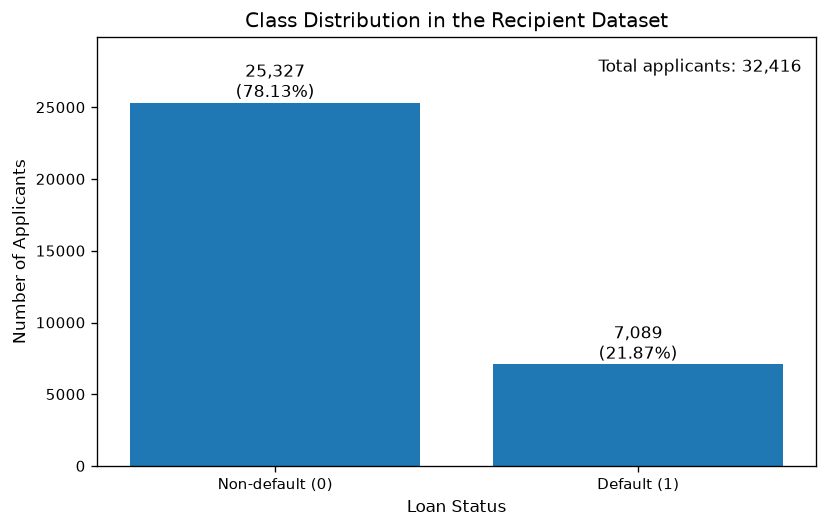

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_04_Experiments\Figure_2_Original_Test_PRAUC.png


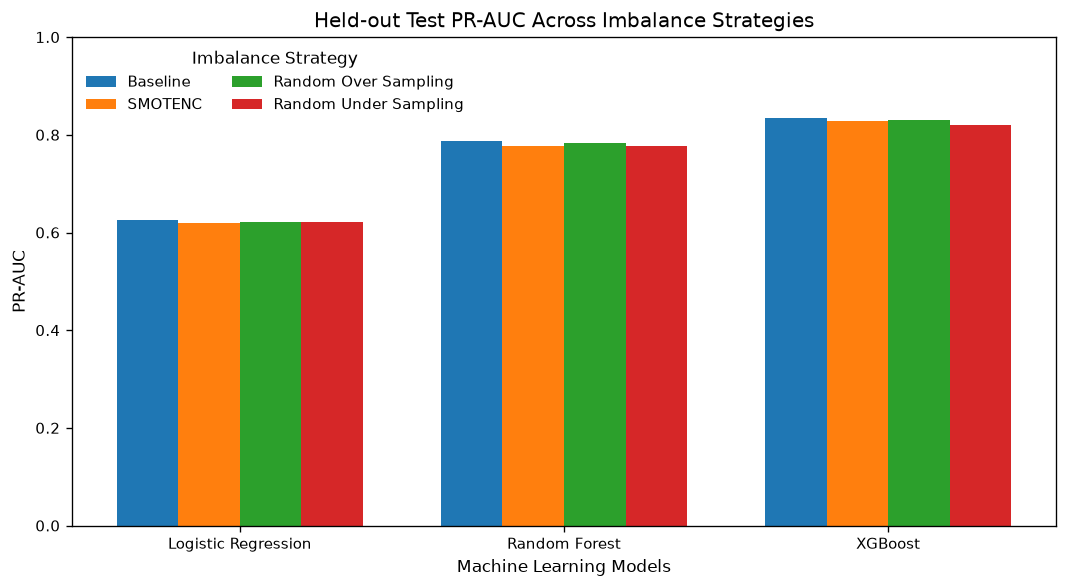

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_04_Experiments\Figure_3_Fusion_Baseline_PRAUC.png


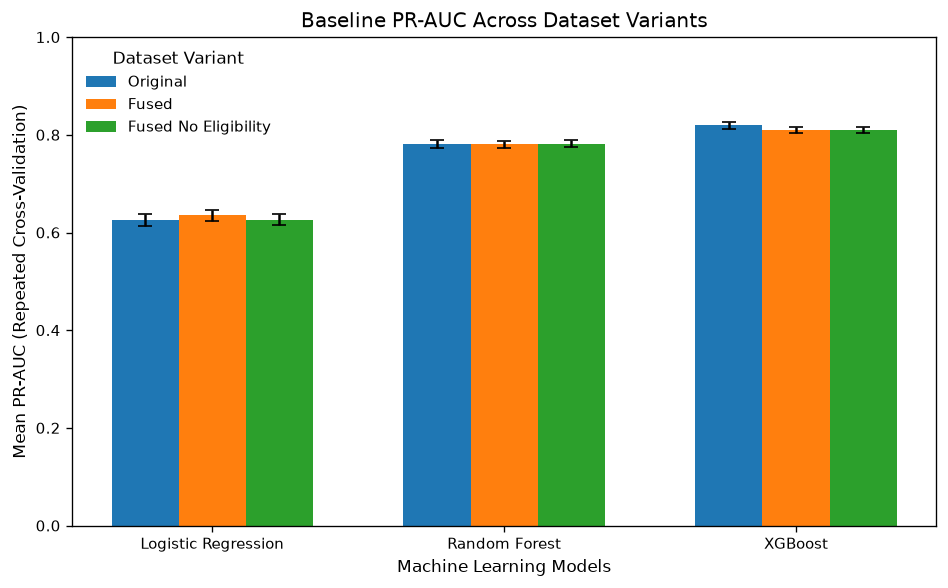

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_04_Experiments\Figure_4_Placebo_Comparison.png


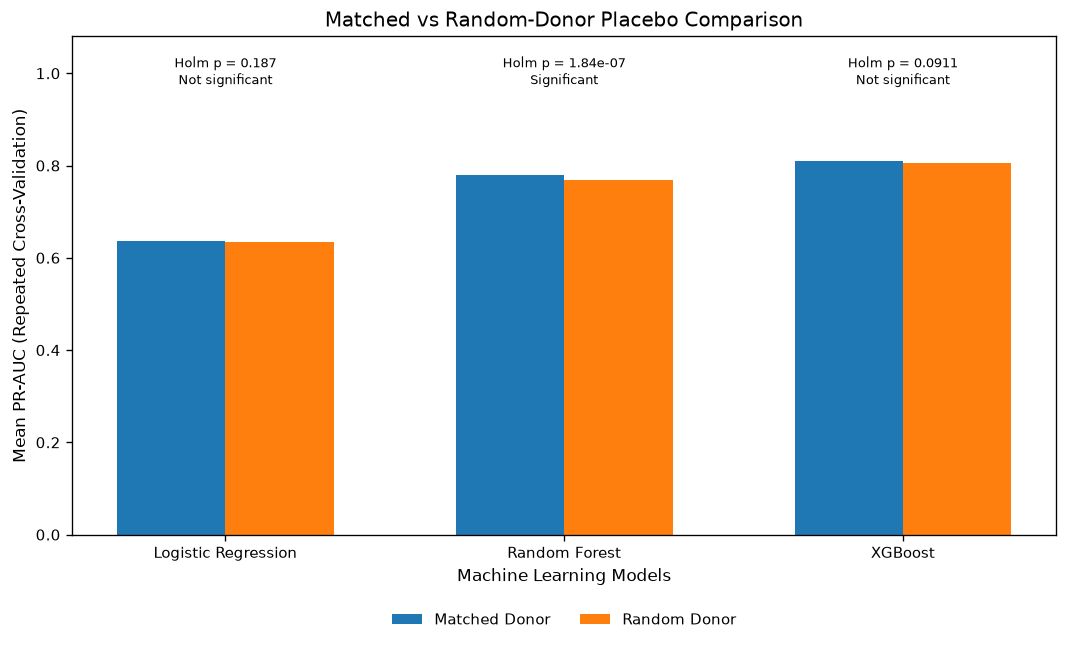


ALL VISUALIZATIONS GENERATED SUCCESSFULLY

Saved figures:
Figure_1_Class_Distribution.png
Figure_2_Original_Test_PRAUC.png
Figure_3_Fusion_Baseline_PRAUC.png
Figure_4_Placebo_Comparison.png

Figure directory: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_04_Experiments


In [35]:
# ============================================================
# VISUALIZATION OF EXPERIMENTAL RESULTS
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

# Create output directory
figures_dir = (
    Path(results_dir) / "figures" / "Notebook_04_Experiments"
)
figures_dir.mkdir(parents=True, exist_ok=True)

# Load experimental results
final_test_df = pd.read_csv(
    Path(results_dir) / "final_test_results.csv"
)

cv_summary_df = pd.read_csv(
    Path(results_dir) / "repeated_cv_summary.csv"
)

placebo_cv = pd.read_csv(
    Path(results_dir) / "random_donor_placebo_cv_results.csv"
)

placebo_tests = pd.read_csv(
    Path(results_dir) / "random_donor_placebo_statistical_tests.csv"
)

# General plotting settings
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9
})


def save_figure(filename):
    plt.tight_layout()

    figure_path = figures_dir / f"{filename}.png"

    plt.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    print(f"Figure saved: {figure_path}")

    plt.show()
    plt.close()


# ============================================================
# FIGURE 1: CLASS DISTRIBUTION
# ============================================================

class_counts = (
    df_original["loan_status"]
    .value_counts()
    .sort_index()
)

class_labels = ["Non-default (0)", "Default (1)"]

fig, ax = plt.subplots(figsize=(7, 4.5))

bars = ax.bar(class_labels, class_counts.values)

ax.set_title("Class Distribution in the Recipient Dataset")
ax.set_xlabel("Loan Status")
ax.set_ylabel("Number of Applicants")

ax.set_ylim(0, class_counts.max() * 1.18)

for bar, count in zip(bars, class_counts.values):
    percentage = count / class_counts.sum() * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

ax.text(
    0.98,
    0.95,
    f"Total applicants: {class_counts.sum():,}",
    transform=ax.transAxes,
    ha="right",
    va="top"
)

save_figure("Figure_1_Class_Distribution")


# ============================================================
# FIGURE 2: ORIGINAL TEST PR-AUC ACROSS IMBALANCE STRATEGIES
# ============================================================

original_test = final_test_df[
    final_test_df["Dataset"] == "Original"
].copy()

models = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
]

strategies = [
    "Baseline",
    "SMOTENC",
    "Random_Over_Sampling",
    "Random_Under_Sampling"
]

x = np.arange(len(models))
width = 0.19

fig, ax = plt.subplots(figsize=(9, 5))

for i, strategy in enumerate(strategies):

    values = []

    for model in models:

        score = original_test[
            (original_test["Model"] == model) &
            (original_test["Strategy"] == strategy)
        ]["PR_AUC"].iloc[0]

        values.append(score)

    ax.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=strategy.replace("_", " ")
    )

ax.set_title("Held-out Test PR-AUC Across Imbalance Strategies")
ax.set_xlabel("Machine Learning Models")
ax.set_ylabel("PR-AUC")

ax.set_xticks(x)
ax.set_xticklabels(models)

ax.set_ylim(0, 1)

ax.legend(
    title="Imbalance Strategy",
    frameon=False,
    ncol=2
)

save_figure("Figure_2_Original_Test_PRAUC")


# ============================================================
# FIGURE 3: BASELINE PR-AUC ACROSS DATASET VARIANTS
# ============================================================

baseline_cv = cv_summary_df[
    cv_summary_df["Strategy"] == "Baseline"
].copy()

dataset_variants = [
    "Original",
    "Fused",
    "Fused_No_Eligibility"
]

x = np.arange(len(models))
width = 0.23

fig, ax = plt.subplots(figsize=(8, 5))

for i, dataset in enumerate(dataset_variants):

    subset = baseline_cv[
        baseline_cv["Dataset"] == dataset
    ].set_index("Model")

    means = [
        subset.loc[model, "PR_AUC_MEAN"]
        for model in models
    ]

    stds = [
        subset.loc[model, "PR_AUC_STD"]
        for model in models
    ]

    ax.bar(
        x + (i - 1) * width,
        means,
        width,
        yerr=stds,
        capsize=4,
        label=dataset.replace("_", " ")
    )

ax.set_title("Baseline PR-AUC Across Dataset Variants")
ax.set_xlabel("Machine Learning Models")
ax.set_ylabel("Mean PR-AUC (Repeated Cross-Validation)")

ax.set_xticks(x)
ax.set_xticklabels(models)

ax.set_ylim(0, 1)

ax.legend(
    title="Dataset Variant",
    frameon=False
)

save_figure("Figure_3_Fusion_Baseline_PRAUC")


# ============================================================
# FIGURE 4: MATCHED VS RANDOM-DONOR PLACEBO COMPARISON
# ============================================================

placebo_means = (
    placebo_cv[
        placebo_cv["Dataset"].isin([
            "Matched_Fused",
            "Random_Donor_Fused"
        ])
    ]
    .groupby(["Dataset", "Model"])["PR_AUC"]
    .mean()
    .reset_index()
)

x = np.arange(len(models))
width = 0.32

fig, ax = plt.subplots(figsize=(9, 5.5))

for i, (dataset, label) in enumerate([
    ("Matched_Fused", "Matched Donor"),
    ("Random_Donor_Fused", "Random Donor")
]):

    subset = placebo_means[
        placebo_means["Dataset"] == dataset
    ].set_index("Model")

    values = [
        subset.loc[model, "PR_AUC"]
        for model in models
    ]

    ax.bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=label
    )

ax.set_title("Matched vs Random-Donor Placebo Comparison")
ax.set_xlabel("Machine Learning Models")
ax.set_ylabel("Mean PR-AUC (Repeated Cross-Validation)")

ax.set_xticks(x)
ax.set_xticklabels(models)

ax.set_ylim(0, 1.08)

# Statistical significance annotations
test_lookup = placebo_tests.set_index("Model")

for i, model in enumerate(models):

    p_value = test_lookup.loc[model, "Holm_P_Value"]
    significant = test_lookup.loc[model, "Significant"]

    status = (
        "Significant"
        if significant
        else "Not significant"
    )

    ax.text(
        i,
        1.04,
        f"Holm p = {p_value:.3g}\n{status}",
        ha="center",
        va="top",
        fontsize=8
    )

# Place legend below the chart to prevent overlap
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=2,
    frameon=False
)

save_figure("Figure_4_Placebo_Comparison")


# ============================================================
# FINAL OUTPUT
# ============================================================

print("\nALL VISUALIZATIONS GENERATED SUCCESSFULLY")

print("\nSaved figures:")

for file in sorted(figures_dir.iterdir()):
    print(file.name)

print("\nFigure directory:", figures_dir)